# Курьер в городе со случайным трафиком

## Что требуется сделать

Нужно построить карту реального города
размером не менее 50 x 50 клеток, задать **три старта и три стратегии курьера**.
Машины появляются случайно и мешают доставке. Нужно сравнить вероятность успеха и скорость
доставки при разной интенсивности трафика: минимум 100 эпизодов на каждый из пяти seed.
Обучения нейросети в этой работе нет: правила стратегий задаём сами.

**Наш вариант:** центр Павлодара, сетка 160 x 160, одна общая цель, шесть источников машин,
четыре вероятности появления машин, всего 18 000 эпизодов.

Разделы идут в порядке выполнения: **карта -> среда -> стратегии -> эксперимент -> графики -> GIF -> выводы**.

`RoadMap` хранит карту, `Car` - одну машину, `Environment` - состояние одной поездки.

`data/` содержит исходную карту OSM и созданную сетку; `results/` - CSV, картинки и GIF.
Карту создаёт отдельный `build_map.py`; ноутбук читает готовые файлы и выполняет симуляцию и анализ.


## 1. Библиотеки и параметры

In [1]:
# Очередь клеток для поиска в ширину.
from collections import deque
# Краткая запись класса с полями машины.
from dataclasses import dataclass
# Очередь клеток по цене пути для алгоритма Дейкстры.
from heapq import heappop, heappush
# Пути к файлам и папкам.
from pathlib import Path

# Построение графиков и схем карты.
import matplotlib.pyplot as plt
# Поиск шрифта для русских подписей.
from matplotlib import font_manager
# Цветные образцы в легендах графиков.
from matplotlib.patches import Patch, Rectangle
# Массивы клеток, вычисления и случайные числа.
import numpy as np
# Таблицы результатов и работа с CSV.
import pandas as pd
# Изображения, рисование и шрифты для GIF.
from PIL import Image as PILImage, ImageDraw, ImageFont, ImageColor
# Показ картинок и таблиц в ноутбуке.
from IPython.display import display
# Ссылки на GIF и небольшие кадры для просмотра в ноутбуке.
from IPython.display import FileLink, Image

# Папка с исходными данными OSM и созданной картой.
DATA_DIR = Path("data")
# Папка с результатами: CSV, графиками и GIF.
RESULTS_DIR = Path("results")
# Создаём папки; exist_ok=True разрешает использовать уже существующие.
DATA_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

# Вероятности появления машины в каждом источнике за один шаг.
SPAWN_PROBABILITIES = (0, 0.005, 0.02, 0.05)
# Начальные числа для повторения случайных сценариев.
RANDOM_SEEDS = (2026, 2027, 2028, 2029, 2030)
# Поездок для каждого сочетания вероятности, старта, стратегии и seed.
EPISODES_PER_SEED = 100
# Максимум шагов одной поездки; затем фиксируем исход "лимит".
MAX_EPISODE_STEPS = 4000

# Действие -> изменение (строки, столбца). Номер строки растёт вниз.
ACTION_OFFSETS = {
    "up": (-1, 0), "down": (1, 0),
    "left": (0, -1), "right": (0, 1), "stop": (0, 0),
}
# Смещения для поиска четырёх соседних клеток дороги; диагоналей нет.
NEIGHBOR_OFFSETS = ((-1, 0), (1, 0), (0, -1), (0, 1))
# Внутренние имена трёх стратегий.
STRATEGIES = ("explorer", "shortest_path", "traffic_aware")
# Русские подписи стратегий в таблицах, графиках и GIF.
STRATEGY_NAMES = {
    "explorer": "Исследователь",
    "shortest_path": "Нетерпеливый кратчайший",
    "traffic_aware": "Осторожный объезд",
}
# Цвета в порядке STRATEGIES: фиолетовый, оранжевый, зелёный.
STRATEGY_COLORS = ("#8d62bd", "#e39337", "#219882")
# Русские названия возможных исходов поездки.
OUTCOME_NAMES = {"success": "доставка", "collision": "авария", "timeout": "лимит шагов"}

## 2. Готовая карта

Источник данных и подложки: OpenStreetMap

Построение вынесено в [build_map.py](build_map.py). Скрипт загружает дороги OpenStreetMap, переводит их в связную сетку 160 x 160 и сохраняет карту и изображения в `data/`.
Старты и цель заданы координатами. Источники выбираются случайно среди дорожных клеток с `TRAFFIC_SOURCE_SEED = 2026`, независимо от пути к цели. Чтобы получить новые источники, измените seed, запустите `build_map.py` и затем весь ноутбук.

Файлы карты уже включены в проект. После установки `requirements.txt` можно сразу выполнить все ячейки сверху вниз. `python build_map.py` нужен только для изменения или повторного построения карты.

Коды в `citymap.txt`: `0` - дорога, `1` - препятствие, `2` - старт, `3` - источник машин, `4` - цель.
В текущем сценарии три старта и одна общая цель.

Подложка OSM показывает город; проходимость задаёт отдельная клеточная сетка. Ступеньки вместо диагоналей нужны для движения вверх, вниз, влево и вправо. Красный медицинский плюс относится к подложке, источники нашей модели обозначены синими квадратами.

In [2]:
# Читаем готовую карту. Для её создания отдельно запускается build_map.py.
map_rows = (DATA_DIR / "citymap.txt").read_text(encoding="utf-8").splitlines()
map_codes = np.array([list(row) for row in map_rows])
print("Размер карты:", map_codes.shape)
print("Дорожных клеток:", (map_codes != "1").sum())

# Находим координаты меток прямо в файле карты.
map_markers = []
marker_names = {"2": "Старт ", "3": "Т", "4": "Цель "}
# Перебираем старты, источники и цель.
for code, name in marker_names.items():
    positions = np.argwhere(map_codes == code)
    # Записываем каждую найденную точку в таблицу.
    for number, (row, column) in enumerate(positions, 1):
        map_markers.append([name + str(number), row, column])
display(pd.DataFrame(map_markers, columns=["Объект", "Строка (с 0)", "Столбец (с 0)"]))

Размер карты: (160, 160)
Дорожных клеток: 2226


,Объект,Строка (с 0),Столбец (с 0)
0,Старт 1,8,14
1,Старт 2,100,125
2,Старт 3,154,9
3,Т1,7,14
4,Т2,40,16
5,Т3,79,133
6,Т4,89,73
7,Т5,108,140
8,Т6,135,8
9,Цель 1,24,159


**Исходная подложка OpenStreetMap**

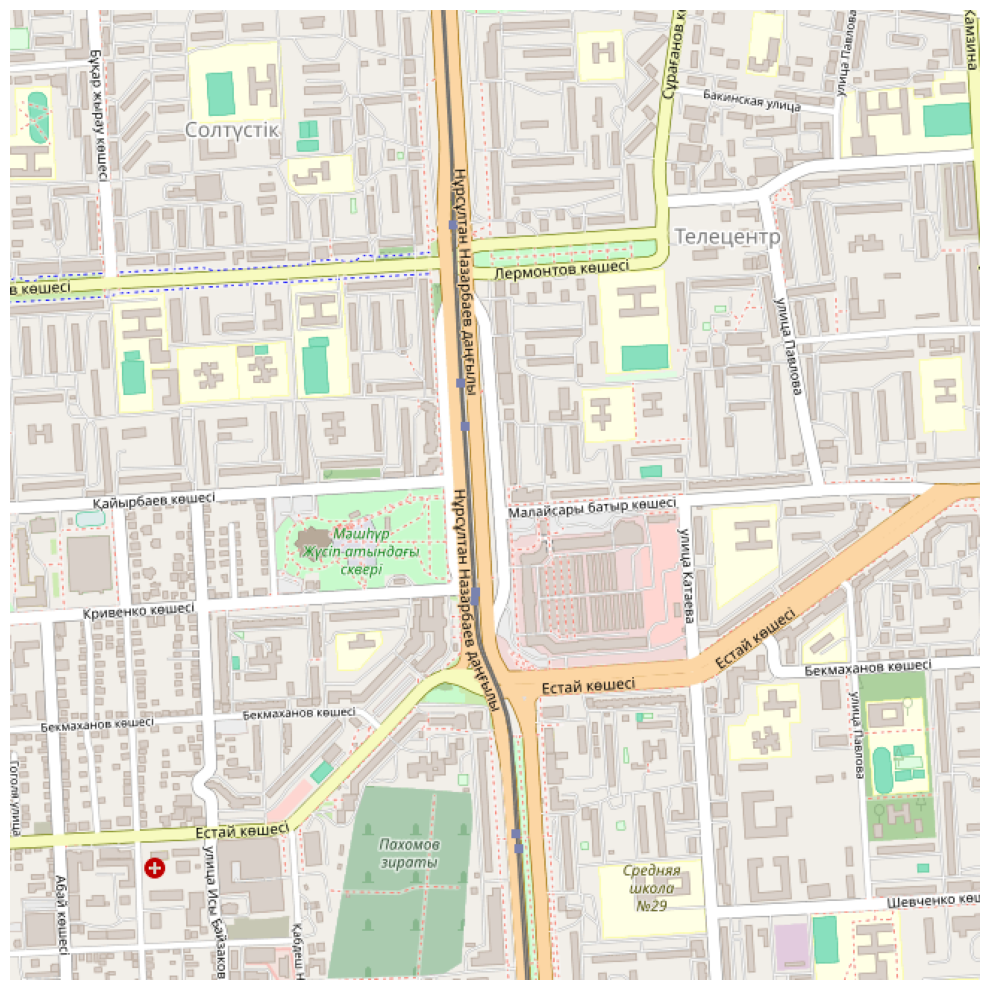

In [3]:
# Показываем готовое изображение карты.
figure, axis = plt.subplots(figsize=(10, 10))
axis.imshow(PILImage.open(DATA_DIR / "source_osm_map.png"))
axis.axis("off")
plt.tight_layout()
plt.show()

**Выбранные дороги OSM как линии**

Каждая линия соединяет точки дороги по долготе и широте. Здесь показаны только выбранные типы дорог. Следующие изображения покажут, какие клетки сетки заняли эти дороги.

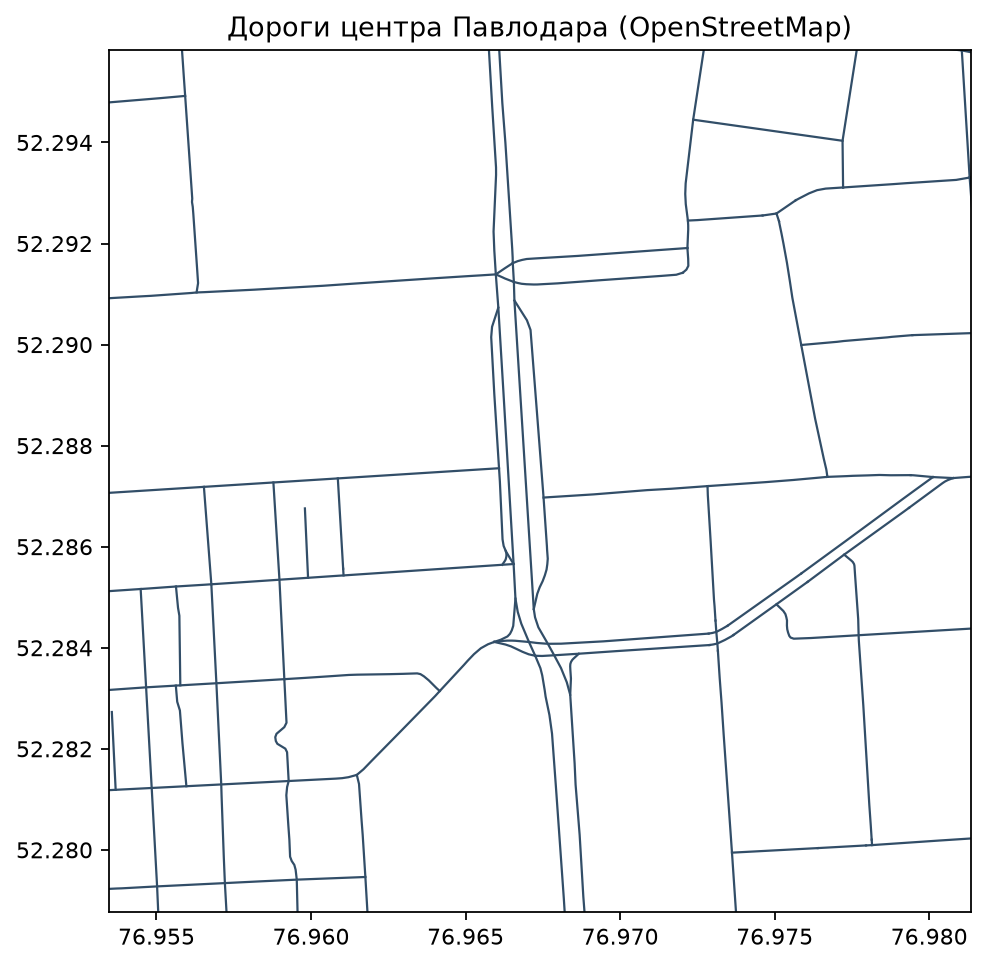

In [4]:
# Показываем выбранные дороги OSM как линии до перевода в клетки.
display(PILImage.open(DATA_DIR / "source_roads.png"))

**Клетки дорог поверх подложки**

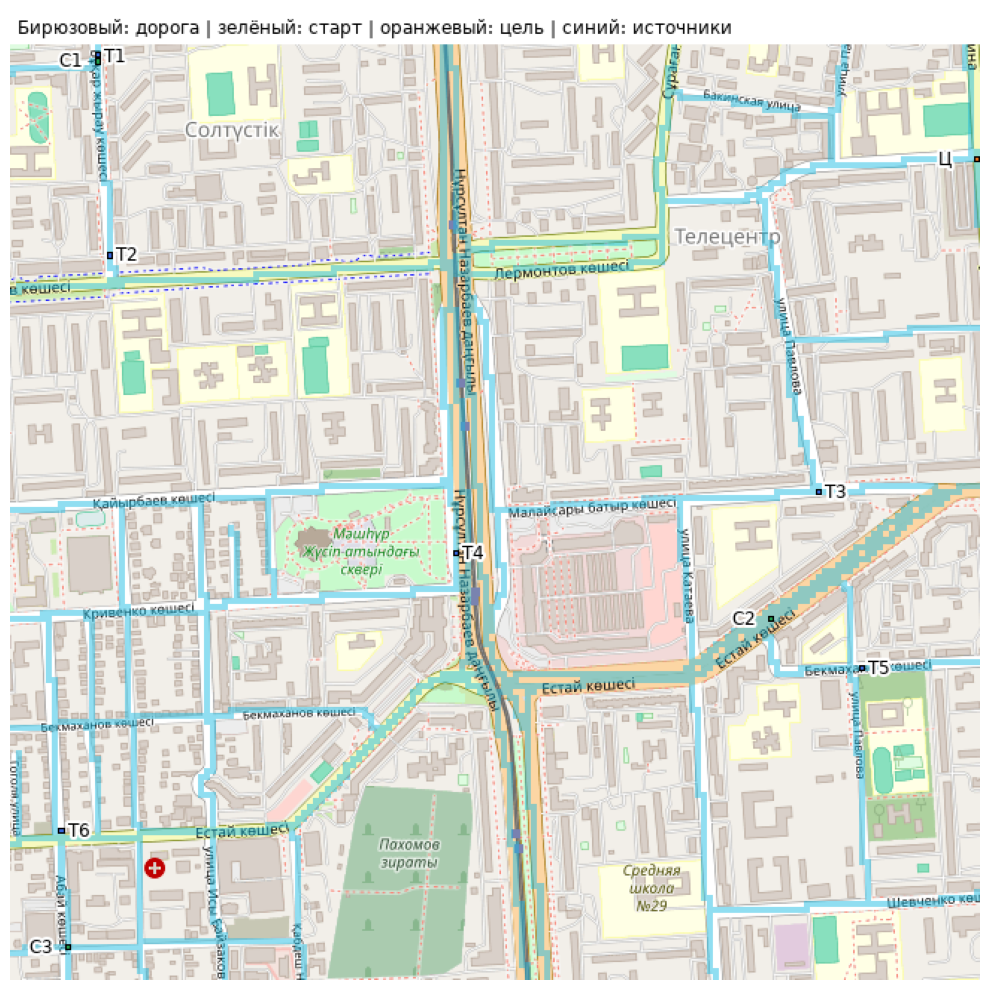

In [5]:
# Показываем готовое изображение карты.
figure, axis = plt.subplots(figsize=(10, 10))
axis.imshow(PILImage.open(DATA_DIR / "overlay_map.png"))
axis.axis("off")
plt.tight_layout()
plt.show()

**Карта, по которой движется курьер**

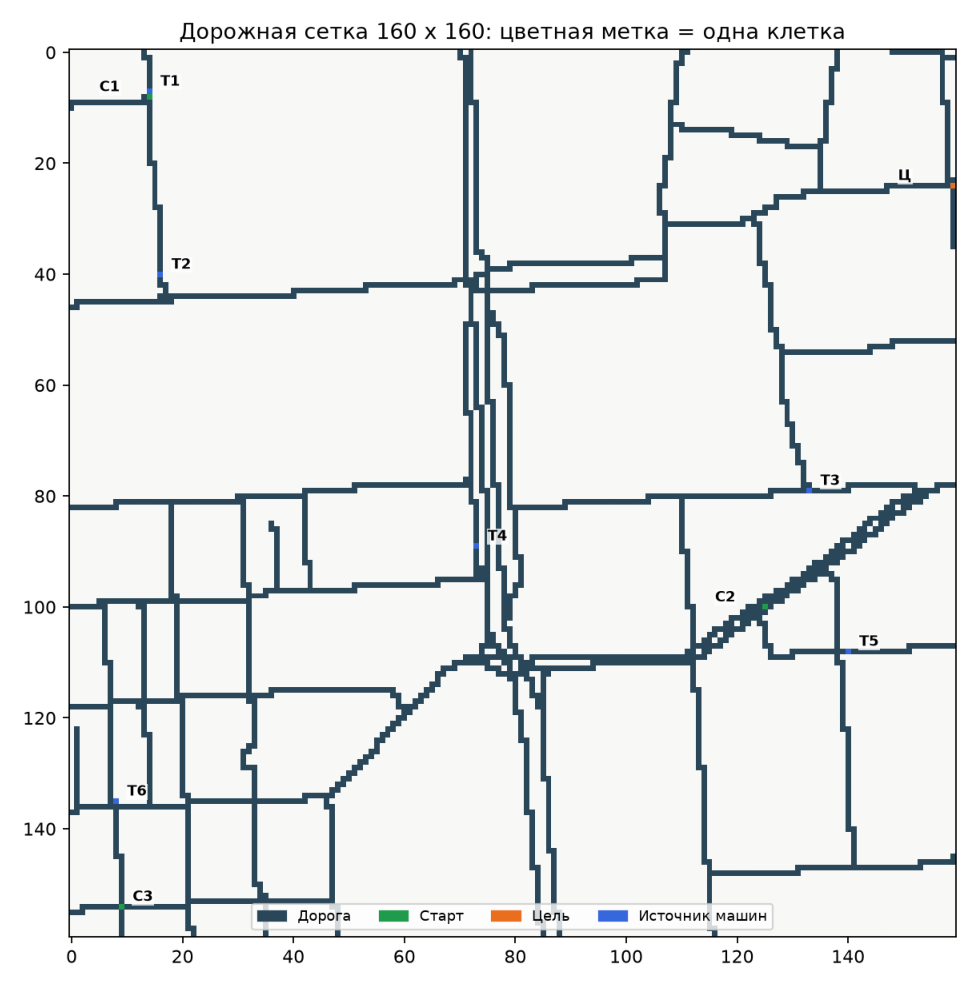

In [6]:
# Показываем готовое изображение карты.
figure, axis = plt.subplots(figsize=(10, 10))
axis.imshow(PILImage.open(DATA_DIR / "grid_map.png"))
axis.axis("off")
plt.tight_layout()
plt.show()

## 3. Среда: что происходит за один шаг

1. Курьер выбирает действие и переходит в соседнюю клетку или остаётся на месте.
2. Если он попал на машину - авария; если на цель - доставка. Эпизод заканчивается.
3. Машины двигаются. Машина, достигшая срока жизни, исчезает после своего последнего хода.
   Если машина прошла через клетку курьера, это тоже авария.
4. Каждый источник с вероятностью `p` создаёт машину со сроком жизни 15-150 шагов.
   Появление машины на клетке курьера тоже означает аварию.

Машины выбирают ход независимо друг от друга. Если после движения или появления
несколько машин оказались в одной клетке, все они исчезают. На развилке направления
равновероятны, включая обратное; в тупике остаётся один выход. На обычной дороге вероятность
продолжить прежнее направление равна 0,70, если оно доступно.
Встречный обмен клетками считается аварией: курьер сначала попадает на ещё занятую клетку машины.

### 3.1. Карта и заранее рассчитанные расстояния

Храним список соседей каждой клетки, чтобы не искать их заново миллионы раз.
Поиск в ширину от цели даёт кратчайшие расстояния. Такой же поиск сразу от всех источников
даёт расстояние до ближайшего источника. Затем алгоритм Дейкстры считает цену пути с надбавкой
за близость к источникам: очередь всегда выбирает клетку с наименьшей накопленной ценой.

In [7]:
# Возвращает соседние клетки дороги внутри карты.
def road_neighbors(cell, road_grid):
    row, column = cell
    neighbors = []

    # Проверяем четыре направления и пропускаем препятствия и край карты.
    for row_step, column_step in NEIGHBOR_OFFSETS:
        next_row = row + row_step
        next_column = column + column_step
        if 0 <= next_row < len(road_grid) and 0 <= next_column < len(road_grid[0]):
            if road_grid[next_row, next_column]:
                neighbors.append((next_row, next_column))
    return neighbors


# Число шагов от start до каждой доступной клетки дороги.
def road_distances(road_grid, start_cell):

    # Начинаем поиск с выбранной клетки: расстояние до неё равно нулю.
    distance_from_start = {start_cell: 0}
    queue = deque([start_cell])

    # Обходим клетки по очереди: сначала ближайшие, затем более далёкие.
    while queue:
        cell = queue.popleft()

        # Проверяем соседей текущей клетки и добавляем ещё не посещённые.
        for next_cell in road_neighbors(cell, road_grid):
            # Первое найденное расстояние кратчайшее, поэтому записываем его один раз.
            if next_cell not in distance_from_start:
                distance_from_start[next_cell] = distance_from_start[cell] + 1
                queue.append(next_cell)

    # Возвращаем расстояние до каждой найденной клетки дороги.
    return distance_from_start

In [8]:
class RoadMap:
    """Дорожная сетка, её метки и расстояния для стратегий."""

    # Читаем готовую карту и рассчитываем данные для движения.
    def __init__(self, map_path):
        # Читаем карту, которую создали выше.
        map_rows = Path(map_path).read_text(encoding="utf-8").splitlines()

        # Создаём массив кодов клеток и маску проходимости: препятствие обозначено только единицей.
        self.cell_codes = np.array([list(row) for row in map_rows])
        self.passable_cells = self.cell_codes != "1"

        # Находим координаты стартов, источников машин и цели по их кодам.
        self.start_cells = [tuple(map(int, cell)) for cell in np.argwhere(self.cell_codes == "2")]
        self.traffic_sources = [tuple(map(int, cell)) for cell in np.argwhere(self.cell_codes == "3")]
        goal_cells = [tuple(map(int, cell)) for cell in np.argwhere(self.cell_codes == "4")]

        self.goal_cell = goal_cells[0]

        # Для каждой дорожной клетки заранее сохраняем доступных соседей.
        self.neighbors_by_cell = {
            tuple(cell): road_neighbors(tuple(cell), self.passable_cells)
            for cell in np.argwhere(self.passable_cells)
        }

        # Находим кратчайшие расстояния до цели по связанной дорожной сетке.
        self.distance_to_goal = road_distances(self.passable_cells, self.goal_cell)

        # Очередь начинает обход сразу от всех источников машин.
        source_distance = {cell: 0 for cell in self.traffic_sources}
        queue = deque(self.traffic_sources)

        # Распространяем расстояния от источников по сети дорог до всех доступных клеток.
        while queue:
            cell = queue.popleft()

            # Проверяем соседей: через текущую клетку к ним может вести новый путь.
            for neighbor_cell in self.neighbors_by_cell[cell]:
                # Записываем только первое посещение: оно даёт расстояние до ближайшего источника.
                if neighbor_cell not in source_distance:
                    source_distance[neighbor_cell] = source_distance[cell] + 1
                    queue.append(neighbor_cell)

        # Возле источника шаг дороже; Дейкстра ищет путь с минимальной суммой цен.
        self.source_aware_cost_to_goal = {self.goal_cell: 0.0}
        frontier = [(0.0, self.goal_cell)]

        # Считаем цену пути до цели, каждый раз выбирая клетку с наименьшей известной ценой.
        while frontier:
            path_cost, cell = heappop(frontier)

            # Пропускаем устаревшую запись, если более дешёвый путь уже найден.
            if path_cost > self.source_aware_cost_to_goal[cell]:
                continue

            # Штраф у источника равен 10 и снижается до нуля на расстоянии 10 дорожных шагов.
            cell_risk = 10 * max(0, 10 - source_distance[cell]) / 10

            # Проверяем соседей: через текущую клетку к ним может вести новый путь.
            for neighbor_cell in self.neighbors_by_cell[cell]:
                # Цена перехода: уже найденный путь плюс один шаг и штраф за близость источника.
                new_cost = path_cost + 1 + cell_risk

                # Обновляем цену соседа только при улучшении; неизвестную цену считаем бесконечной.
                if new_cost < self.source_aware_cost_to_goal.get(neighbor_cell, float("inf")):
                    self.source_aware_cost_to_goal[neighbor_cell] = new_cost
                    heappush(frontier, (new_cost, neighbor_cell))

### 3.2. Машины и состояние поездки

`Car` хранит клетку, предыдущее направление, срок жизни и уже прожитое число шагов.
`Environment` хранит курьера, список машин и исход поездки.
У трафика и стратегии отдельные генераторы случайных чисел: случайный ход курьера
не меняет последующие случайные решения машин.

In [9]:
@dataclass
class Car:
    # Текущая клетка машины: строка и столбец.
    cell: tuple[int, int]

    # Смещение на прошлом ходу; None означает, что машина ещё не двигалась.
    direction: tuple[int, int] | None

    # Сколько шагов машина остаётся в симуляции после появления.
    lifetime: int

    # Сколько шагов уже прошло для этой машины, включая ожидание.
    moves: int = 0

In [10]:
class Environment:
    """Один эпизод: положение курьера, машины, генераторы случайных чисел."""

    # Создаём одну поездку с выбранным стартом и случайными числами.
    def __init__(self, road_map: RoadMap, start_index: int, spawn_probability: float,
                 traffic_seed: int, strategy_seed: int):
        # Сохраняем карту, выбранный старт и интенсивность трафика для новой поездки.
        self.road_map = road_map
        self.courier_cell = road_map.start_cells[start_index]
        self.start_cell = self.courier_cell
        # Помним все посещённые клетки и число входов в каждую из них.
        self.visit_counts = {self.start_cell: 1}
        self.spawn_probability = spawn_probability
        # Разные генераторы отделяют случайность трафика от выбора курьера.
        self.traffic_rng = np.random.default_rng(traffic_seed)
        self.strategy_rng = np.random.default_rng(strategy_seed)

        # Начинаем без машин, с нулевым счётчиком шагов и без завершённого исхода.
        self.cars: list[Car] = []
        self.steps = 0
        self.outcome: str | None = None

    # Удаляет все машины из клеток, где встретились две или больше машин.
    def _remove_car_collisions(self):
        occupied_cells = set()
        collision_cells = set()

        # Находим клетки, в которых оказались несколько машин.
        for car in self.cars:
            if car.cell in occupied_cells:
                collision_cells.add(car.cell)
            occupied_cells.add(car.cell)

        # Убираем все машины из этих клеток.
        remaining_cars = []
        for car in self.cars:
            if car.cell not in collision_cells:
                remaining_cars.append(car)
        self.cars = remaining_cars

    # Передвигает машины независимо друг от друга и запоминает пройденные клетки.
    def _move_cars(self):
        visited_by_cars = set()

        # Каждая машина выбирает направление только по форме дороги.
        for car in self.cars:
            neighbor_cells = self.road_map.neighbors_by_cell[car.cell]

            # В тупике есть только один выход.
            if len(neighbor_cells) == 1:
                next_cell = neighbor_cells[0]
            # На развилке все направления, включая обратное, равновероятны.
            elif len(neighbor_cells) >= 3:
                next_cell = neighbor_cells[int(self.traffic_rng.integers(len(neighbor_cells)))]
            else:
                # На обычной дороге машина чаще сохраняет прошлое направление.
                forward_cell = None
                if car.direction is not None:
                    forward_cell = (car.cell[0] + car.direction[0],
                                    car.cell[1] + car.direction[1])
                if forward_cell in neighbor_cells and self.traffic_rng.random() < .70:
                    next_cell = forward_cell
                else:
                    # Если движение прямо возможно, остальные 30% приходятся на поворот.
                    turn_options = neighbor_cells.copy()
                    if forward_cell in turn_options:
                        turn_options.remove(forward_cell)
                    next_cell = turn_options[int(self.traffic_rng.integers(len(turn_options)))]

            # Переносим машину и запоминаем её направление и число прожитых шагов.
            car.direction = (next_cell[0] - car.cell[0], next_cell[1] - car.cell[1])
            car.cell = next_cell
            car.moves += 1
            visited_by_cars.add(car.cell)

        # Сначала убираем столкнувшиеся машины, затем машины с истекшим сроком жизни.
        self._remove_car_collisions()
        self.cars = [car for car in self.cars if car.moves < car.lifetime]
        return visited_by_cars

    # Порядок шага: курьер, машины, затем появление новых машин.
    def step(self, action: str) -> str | None:
        # Переводим выбранное действие курьера в координаты следующей клетки.
        row_change, column_change = ACTION_OFFSETS[action]
        next_courier_cell = (self.courier_cell[0]+row_change, self.courier_cell[1]+column_change)

        # Записываем любой переход, включая отступление; ожидание не считается новым входом.
        if next_courier_cell != self.courier_cell:
            previous_visits = self.visit_counts.get(next_courier_cell, 0)
            self.visit_counts[next_courier_cell] = previous_visits + 1

        # Перемещаем курьера и увеличиваем счётчик шагов поездки.
        self.courier_cell = next_courier_cell
        self.steps += 1
        # Авария возможна и при входе в занятую клетку, и после хода машин.
        if next_courier_cell in {car.cell for car in self.cars}:
            self.outcome = "collision"
        elif next_courier_cell == self.road_map.goal_cell:
            self.outcome = "success"

        # Если поездка завершена, дальнейшие шаги не выполняем.
        if self.outcome is not None:
            return self.outcome

        # Передвигаем машины и проверяем, не прошла ли одна из них через курьера.
        visited_by_cars = self._move_cars()
        if next_courier_cell in visited_by_cars:
            self.outcome = "collision"
            return self.outcome
        # Каждый источник создаёт машину с заданной вероятностью независимо от других машин.
        spawned_on_courier = False
        for traffic_source in self.road_map.traffic_sources:
            if self.traffic_rng.random() < self.spawn_probability:
                # Создаём машину со случайным сроком жизни от 15 до 150 шагов включительно.
                self.cars.append(Car(traffic_source, None, int(self.traffic_rng.integers(15, 151))))
                if traffic_source == next_courier_cell:
                    spawned_on_courier = True

        # Если новая машина появилась на другой машине, обе исчезают.
        self._remove_car_collisions()
        if spawned_on_courier:
            self.outcome = "collision"
        return self.outcome

## 4. Три стратегии курьера

Все стратегии исключают клетки, уже занятые машинами. Близость свободных клеток к машинам каждая стратегия учитывает по-своему. Машины могут переместиться после хода курьера, поэтому авария всё равно возможна.

| Стратегия | Как выбирает маршрут | Как реагирует на машины |
| --- | --- | --- |
| Исследователь | Новые клетки, среди них дальше от цели | В пределах 3 клеток старается удалиться от машины, разрешая возврат |
| Нетерпеливый кратчайший | Кратчайшее расстояние плюс штраф за близкие машины | Продолжает движение, отклоняется от пути; стоит только без доступного шага |
| Осторожный объезд | Путь с надбавкой за близость источников | Ждёт машину в пределах 5 клеток от намеченного шага; отступает, если ждать опасно |

Расстояние до цели считается по дорогам. Для реакции на машины используем сумму разностей строк и столбцов. Это разные расстояния: соседняя улица тоже может вызвать осторожную реакцию.
Все правила заданы вручную; обучения нет.

### 4.1. Исследователь

Обычно выбирает непосещённого соседа, предпочитая большее оставшееся расстояние до цели.
Это желание исследовать, а не поиск математически самого длинного пути.
При опасности отступает от машин, в том числе через старые клетки.
Все посещения сохраняются: ожидание не считается повторным входом.
Если новых выходов нет, выбирает старую соседнюю клетку с наименьшим расстоянием до цели. Если таких клеток несколько, берёт первую в порядке проверки: вверх, вниз, влево, вправо.

In [11]:
# Расстояние по строкам и столбцам без диагоналей.
def grid_distance(first_cell, second_cell):
    row_distance = abs(first_cell[0] - second_cell[0])
    column_distance = abs(first_cell[1] - second_cell[1])
    return row_distance + column_distance


# Возвращает расстояние до ближайшей машины и её клетку.
def find_nearest_car(cell, cars):
    nearest_distance = float("inf")
    nearest_cell = None
    # Сравниваем машины по очереди и запоминаем ближайшую.
    for car in cars:
        distance = grid_distance(cell, car.cell)
        if distance < nearest_distance:
            nearest_distance = distance
            nearest_cell = car.cell
    return nearest_distance, nearest_cell


# Выбирает клетку с наименьшим числом в словаре costs.
def choose_lowest_cost(cells, costs):
    chosen_cell = cells[0]
    # При равенстве оставляем первый вариант: дополнительное правило не требуется.
    for cell in cells:
        if costs[cell] < costs[chosen_cell]:
            chosen_cell = cell
    return chosen_cell

In [12]:
# Исследует новые клетки, а при опасности удаляется от машин.
def choose_explorer_cell(environment, available_cells):
    goal_distances = environment.road_map.distance_to_goal
    car_distance, nearest_car = find_nearest_car(environment.courier_cell, environment.cars)

    # Рядом с машиной важнее расстояние до неё, затем число прошлых посещений.
    if car_distance <= 3:
        environment.decision_note = "УХОЖУ ОТ МАШИН"
        environment.decision_car = nearest_car
        best_distance = -1
        fewest_visits = float("inf")
        chosen_cell = available_cells[0]
        # Ищем самый спокойный выход, разрешая возвращаться на старые клетки.
        for cell in available_cells:
            distance, _ = find_nearest_car(cell, environment.cars)
            visits = environment.visit_counts.get(cell, 0)
            # Более далёкая от машины клетка всегда лучше.
            if distance > best_distance:
                chosen_cell = cell
                best_distance = distance
                fewest_visits = visits
            # При одинаковом расстоянии выбираем менее посещённую.
            elif distance == best_distance and visits < fewest_visits:
                chosen_cell = cell
                fewest_visits = visits
        return chosen_cell

    # Среди новых соседей собираем те, откуда путь до цели длиннее.
    exploration_options = []
    longest_distance = -1
    # Просматриваем соседей по одному, не запрещая будущие возвраты.
    for cell in available_cells:
        if cell in environment.visit_counts:
            continue
        distance = goal_distances[cell]
        if distance > longest_distance:
            exploration_options = [cell]
            longest_distance = distance
        elif distance == longest_distance:
            exploration_options.append(cell)
    if exploration_options:
        environment.decision_note = "ИССЛЕДУЮ НОВУЮ КЛЕТКУ"
        random_index = environment.strategy_rng.integers(len(exploration_options))
        return exploration_options[random_index]

    # Если новых выходов нет, движемся по старым клеткам к цели.
    environment.decision_note = "ВОЗВРАЩАЮСЬ ПО СТАРЫМ КЛЕТКАМ"
    return choose_lowest_cost(available_cells, goal_distances)

### 4.2. Нетерпеливый кратчайший

Оценивает соседнюю клетку: кратчайшее расстояние до цели плюс штраф за машины.
Машина в одной клетке от неё добавляет 6, в двух клетках - 3, дальше - 0. Штрафы суммируются.
Это добавка к оценке, а не запрет: клетка дальше от цели может оказаться выгоднее, если рядом с ней меньше машин.
Все коэффициенты выбраны вручную.

Курьер выбирает доступный шаг с меньшей оценкой и продолжает ехать. Специального ожидания нет.
Если все выходы заняты, приходится стоять.

In [13]:
# Выбирает короткий путь со штрафом за близкие машины.
def choose_shortest_cell(environment, available_cells):
    move_costs = {}
    # Оцениваем каждый доступный шаг отдельно.
    for cell in available_cells:
        cost = environment.road_map.distance_to_goal[cell]
        # Машина в одной клетке добавляет 6, в двух клетках - 3, дальше - 0.
        for car in environment.cars:
            distance = grid_distance(cell, car.cell)
            cost += 3 * max(0, 3 - distance)
        move_costs[cell] = cost
    chosen_cell = choose_lowest_cost(available_cells, move_costs)

    # Сохраняем объяснение выбранного шага для GIF.
    environment.decision_note = "ЕДУ К ЦЕЛИ БЕЗ ОЖИДАНИЯ"
    car_distance, nearest_car = find_nearest_car(chosen_cell, environment.cars)
    if car_distance <= 3:
        environment.decision_note = "НЕ ЖДУ: ВЫБИРАЮ ШАГ РЯДОМ С МАШИНОЙ"
        environment.decision_car = nearest_car
    return chosen_cell

### 4.3. Осторожный объезд

Заранее учитывает источники машин: надбавка за клетку равна
`10 * max(0, 10 - расстояние до ближайшего источника) / 10`.
Так маршрут может обходить опасный участок ещё до появления машины. Штраф 10 выбран вручную: со старта 2 он ведёт в обход источника Т3.
При приближении машины к следующей клетке на расстояние 5 или меньше ждёт, пока текущая клетка безопасна.
Если машина уже рядом с курьером, отступает в доступную клетку. Без трафика использует обычный кратчайший путь.

In [14]:
# Объезжает источники и ждёт приближающиеся машины.
def choose_traffic_aware_cell(environment, neighbor_cells, available_cells, occupied_cells):
    route_costs = environment.road_map.distance_to_goal
    environment.decision_note = "ЕДУ К ЦЕЛИ: МАШИН НЕТ"
    if environment.spawn_probability > 0:
        route_costs = environment.road_map.source_aware_cost_to_goal
        environment.decision_note = "ЕДУ ПО ПУТИ В ОБХОД ИСТОЧНИКОВ"

    # Проверяем машину возле намеченного шага и безопасность текущей клетки.
    planned_cell = choose_lowest_cost(neighbor_cells, route_costs)
    car_distance, nearest_car = find_nearest_car(planned_cell, environment.cars)
    # Ждать можно, только если рядом с курьером сейчас нет машины.
    can_wait = not occupied_cells.intersection(neighbor_cells)
    if can_wait and car_distance <= 5:
        environment.decision_note = "ЖДУ МАШИНУ"
        environment.decision_car = nearest_car
        return environment.courier_cell

    # Когда ждать опасно, продолжаем движение по доступной дороге.
    if not can_wait:
        environment.decision_note = "УХОЖУ: ЖДАТЬ ЗДЕСЬ ОПАСНО"
    return choose_lowest_cost(available_cells, route_costs)

### 4.4. Общий выбор доступных клеток

Сначала отбрасываем клетки, уже занятые машинами. Остальные соседние клетки передаём
выбранной стратегии. Её решение переводим в действие `up`, `down`, `left`, `right` или `stop`.

In [15]:
# Общие ограничения движения и вызов одной из трёх стратегий.
def choose_action(environment, strategy):

    # Очищаем подпись прошлого шага; эти поля нужны только для объяснения анимации.
    environment.decision_note = "НЕТ СВОБОДНОГО ВЫХОДА"
    environment.decision_car = None

    # Собираем соседние дорожные клетки и текущие позиции машин.
    neighbor_cells = environment.road_map.neighbors_by_cell[environment.courier_cell]
    occupied_cells = {car.cell for car in environment.cars}

    available_cells = []
    # Исключаем только занятые клетки; соседние машины каждая стратегия учитывает сама.
    for cell in neighbor_cells:
        if cell not in occupied_cells:
            available_cells.append(cell)

    # Если некуда перейти, выбираем остановку.
    if not available_cells:
        return "stop"

    # Передаём подготовленные клетки выбранной стратегии.
    if strategy == "explorer":
        next_cell = choose_explorer_cell(environment, available_cells)
    elif strategy == "shortest_path":
        next_cell = choose_shortest_cell(environment, available_cells)
    else:
        next_cell = choose_traffic_aware_cell(
            environment, neighbor_cells, available_cells, occupied_cells)

    # По выбранной клетке определяем смещение и соответствующее ему действие курьера.
    move_offset = (next_cell[0] - environment.courier_cell[0],
                   next_cell[1] - environment.courier_cell[1])
    # Находим название действия по смещению строки и столбца.
    for action, offset in ACTION_OFFSETS.items():
        if offset == move_offset:
            return action

## 5. Одна поездка и проверка без трафика

`run_episode` повторяет "выбрать действие -> сделать шаг" до доставки, аварии или лимита 4000 шагов.
При `record=True` дополнительно сохраняются клетки курьера и машин для каждого кадра.
На массовом эксперименте кадры не нужны и не занимают память.

In [16]:
# Запускает один эпизод; record сохраняет кадры для анимации.
def run_episode(road_map: RoadMap, start_index: int, spawn_probability: float, traffic_seed: int,
                strategy_seed: int, strategy: str, max_steps: int, record=False):

    # Создаём новую поездку с заданным стартом, трафиком и случайными числами.
    environment = Environment(road_map, start_index, spawn_probability, traffic_seed, strategy_seed)

    # Если нужна анимация, сохраняем начальное положение ещё до первого шага.
    animation_frames = []
    if record:
        animation_frames.append((environment.courier_cell, ()))

    # Записываем решение до хода, чтобы подпись соответствовала видимым позициям машин.
    decision_frames = []

    # Повторяем выбор действия и ход среды, пока не закончится поездка или лимит шагов.
    for _ in range(max_steps):
        action = choose_action(environment, strategy)
        if record:
            decision_frames.append({"action": action, "note": environment.decision_note,
                                    "car": environment.decision_car})
        environment.step(action)

        # Для будущего кадра запоминаем положение курьера и всех оставшихся машин.
        if record:
            animation_frames.append((environment.courier_cell, tuple(car.cell for car in environment.cars)))

        # Останавливаем цикл сразу после доставки или аварии.
        if environment.outcome is not None:
            break

    # После завершения нет следующего решения: последняя подпись сообщает исход.
    if record:
        decision_frames.append({"action": None, "note": OUTCOME_NAMES[environment.outcome or "timeout"].upper(),
                                "car": None})

    # Возвращаем исход, число шагов и кадры; отсутствие исхода означает исчерпанный лимит.
    return {"outcome": environment.outcome or "timeout",
            "steps": environment.steps, "frames": animation_frames, "decisions": decision_frames}

In [17]:
# Загружаем готовую сетку в объект карты для симуляции.
road_map = RoadMap(DATA_DIR / "citymap.txt")
# Без машин каждая стратегия должна суметь доставить груз из всех трёх стартов.
for start_index, start_cell in enumerate(road_map.start_cells):
    # Из текущего старта запускаем каждую стратегию без машин и собираем исходы.
    outcomes = [run_episode(road_map, start_index, 0, 1, 2, strategy, MAX_EPISODE_STEPS)["outcome"]
                for strategy in STRATEGIES]

    # Проверяем, что все три поездки завершились доставкой.
    assert outcomes == ["success"] * 3, f"Не пройдена проверка старта {start_index + 1}"
    print(f"Старт {start_index + 1}: кратчайший путь - {road_map.distance_to_goal[start_cell]} шагов; "
          "все три стратегии доставили груз без трафика.")

Старт 1: кратчайший путь - 201 шагов; все три стратегии доставили груз без трафика.
Старт 2: кратчайший путь - 170 шагов; все три стратегии доставили груз без трафика.
Старт 3: кратчайший путь - 286 шагов; все три стратегии доставили груз без трафика.


## 6. Массовый эксперимент

Для каждого из 3 стартов, 3 стратегий и 4 вероятностей трафика проведено 100 поездок при каждом из 5 seed: всего 18 000 поездок. Результаты сохранены в results/episodes.csv.

Сравниваем два показателя: долю доставок среди всех поездок и среднее число шагов успешной доставки. Меньше шагов означает быстрее. Аварии в среднее время доставки не входят, поэтому оба показателя нужно читать вместе.

Каждый ящик диаграммы размаха содержит пять значений: по одному на seed, каждый из которых объединяет 100 поездок. Лимит поездки равен 4000 шагов.

In [18]:
# Получает воспроизводимое начальное число генератора случайности.
def make_episode_seed(*seed_components):

    # Смешиваем номера условий и эпизода в одно число: одинаковые входы дают одинаковый seed.
    return int(np.random.SeedSequence(seed_components).generate_state(1)[0])

In [19]:
# Перебирает все условия и сохраняет одну строку на поездку.
def run_experiment(road_map, output_dir):

    # Подготавливаем список: в нём будет одна строка на каждую поездку.
    episode_rows = []

    # Перебираем четыре уровня интенсивности трафика.
    for probability_index, spawn_probability in enumerate(SPAWN_PROBABILITIES):
        # Для каждого уровня трафика проверяем все три старта.
        for start_index in range(3):
            # Повторяем опыт с пятью разными начальными числами случайности.
            for base_seed in RANDOM_SEEDS:
                # В каждом наборе проводим 100 отдельных поездок для каждой стратегии.
                for episode_index in range(EPISODES_PER_SEED):
                    # Начальное число трафика одинаково для трёх стратегий.
                    traffic_seed = make_episode_seed(base_seed, probability_index, start_index, episode_index, 0)

                    # Сравниваем три стратегии при одинаковом начальном числе трафика.
                    for strategy_index, strategy in enumerate(STRATEGIES):
                        # Для случайных решений каждой стратегии выделяем отдельный seed.
                        strategy_seed = make_episode_seed(
                            base_seed, probability_index, start_index, episode_index, strategy_index + 1)
                        episode_result = run_episode(
                            road_map, start_index, spawn_probability, traffic_seed,
                            strategy_seed, strategy, MAX_EPISODE_STEPS)

                        # Записываем условия опыта, исход поездки и затраченное число шагов.
                        episode_rows.append((spawn_probability, start_index + 1, strategy, base_seed,
                                             episode_index, episode_result["outcome"], episode_result["steps"]))

        # Сообщаем о завершении расчётов для текущей интенсивности трафика.
        print(f"Готово: p = {spawn_probability:g}; накоплено поездок {len(episode_rows)}", flush=True)

    # Преобразуем все записи в таблицу и сохраняем её в CSV.
    episode_results = pd.DataFrame(episode_rows, columns=(
        "rate", "start", "policy", "seed", "episode", "outcome", "steps"))
    episode_results.to_csv(output_dir / "episodes.csv", index=False)
    return episode_results

In [20]:
# Считает показатели отдельно для каждого seed по 100 эпизодам.
def summarize_by_seed(episode_results, output_dir):

    # Подготавливаем итоговую таблицу: одна строка на 100 поездок одного набора.
    summary_rows = []

    # Группируем поездки с одинаковыми вероятностью, стартом, стратегией и seed.
    for (spawn_probability, start_number, strategy, base_seed), matching_episodes in episode_results.groupby(
            ["rate", "start", "policy", "seed"]):
        # Отдельно выбираем доставки, чтобы посчитать их количество и среднее время.
        successful_episodes = matching_episodes[matching_episodes.outcome == "success"]
        # Время доставки считаем только для успешных поездок.
        summary_rows.append((spawn_probability, start_number, strategy, base_seed,
                             len(successful_episodes) / len(matching_episodes),
                             successful_episodes.steps.mean()))

    # Даём названия показателям и сохраняем сводную таблицу по seed.
    seed_summary = pd.DataFrame(summary_rows, columns=(
        "rate", "start", "policy", "seed", "success", "successful_steps"))
    seed_summary.to_csv(output_dir / "seed_summary.csv", index=False)
    return seed_summary

In [21]:
# Запускаем полный эксперимент и вычисляем показатели для каждого seed.
episode_results = run_experiment(road_map, RESULTS_DIR)
seed_summary = summarize_by_seed(episode_results, RESULTS_DIR)

# Показываем объём расчёта, число поездок на условие и случаи достижения лимита.
print("Всего эпизодов:", len(episode_results))
print("Минимум эпизодов на сочетание условий:",
      episode_results.groupby(["rate", "start", "policy", "seed"]).size().min())
print("Поездок с исчерпанным лимитом:", (episode_results.outcome == "timeout").sum())

# Проверяем, что для каждой точки графика есть успешные доставки.
print("Минимум доставок на точку графика:",
      episode_results.assign(success=episode_results.outcome == "success")
      .groupby(["rate", "start", "policy"]).success.sum().min())

Готово: p = 0; накоплено поездок 4500


Готово: p = 0.005; накоплено поездок 9000


Готово: p = 0.02; накоплено поездок 13500


Готово: p = 0.05; накоплено поездок 18000


Всего эпизодов: 18000
Минимум эпизодов на сочетание условий: 100
Поездок с исчерпанным лимитом: 0
Минимум доставок на точку графика: 163


## 7. Графики и сравнение маршрутов

Каждая ячейка показывает один график. Две короткие функции содержат повторяющееся оформление линий и boxplot.
На линейных графиках значения `p` расположены равномерно как четыре условия эксперимента;
их численные значения подписаны на оси. Цвет, форма точки и стиль линии различают стратегии,
даже когда их результаты почти совпадают.

**Как читать boxplot:** цветной прямоугольник - средние 50% значений, линия внутри - медиана,
усы - значения в пределах 1,5 межквартильного размаха, отдельные точки - выбросы.
Чёрная точка дополнительно показывает среднее. Если все пять значений равны, ящик превращается в линию -
например, при 100% доставок без трафика.
При совпадении всех пяти значений цветное кольцо сохраняет цвет стратегии вокруг точки среднего.

In [22]:
# Условие эксперимента - один старт, одна стратегия и одно значение p.
# Объединяем 500 поездок этого условия по пяти seed для точек графиков.
condition_summary = episode_results.assign(delivered=episode_results.outcome == "success").groupby(
    ["start", "policy", "rate"]).agg(
        episode_count=("outcome", "size"), delivery_count=("delivered", "sum"))
condition_summary["success_percent"] = 100 * condition_summary.delivery_count / condition_summary.episode_count

# Время доставки считаем только по успешным поездкам; при их отсутствии остаётся NaN.
condition_summary["successful_steps"] = episode_results[episode_results.outcome == "success"].groupby(
    ["start", "policy", "rate"]).steps.mean()

# Готовим одинаковые подписи и обозначения для всех графиков.
rate_positions = np.arange(len(SPAWN_PROBABILITIES))
rate_labels = [str(probability).replace(".", ",") for probability in SPAWN_PROBABILITIES]
plot_styles = (("o", "--"), ("s", "-."), ("^", "-"))
strategy_legend = [Patch(color=color, label=STRATEGY_NAMES[strategy])
                   for strategy, color in zip(STRATEGIES, STRATEGY_COLORS)]

In [23]:
# Строит один график, который вызывается из своей ячейки.
def show_metric_plot(start_number, metric_name, title, y_label):
    figure, axis = plt.subplots(figsize=(10, 5))
    # Рисуем все три стратегии; смещение разделяет совпадающие точки.
    for strategy_index, (strategy, color) in enumerate(zip(STRATEGIES, STRATEGY_COLORS)):
        values = condition_summary.loc[(start_number, strategy)][metric_name]
        values = values.reindex(SPAWN_PROBABILITIES)
        marker, line_style = plot_styles[strategy_index]
        positions = rate_positions + (strategy_index - 1) * .06
        axis.plot(positions, values, marker=marker, linestyle=line_style,
                  color=color, label=STRATEGY_NAMES[strategy])
        # Не заменяем отсутствующее время доставки выдуманным нулём.
        for rate_index, value in enumerate(values):
            if pd.isna(value):
                axis.text(rate_index, .05 + strategy_index * .06, "Нет доставок",
                          color=color, transform=axis.get_xaxis_transform(), ha="center")

    # Шкала шагов учитывает длинные поездки исследователя.
    axis.set_ylim(bottom=0)
    if metric_name == "success_percent":
        axis.set_ylim(-3, 103)
    elif metric_name == "successful_steps":
        axis.set_yscale("log")
        axis.set_yticks([100, 200, 500, 1000, 2000, 4000], ["100", "200", "500", "1000", "2000", "4000"])
        axis.set_ylim(100, MAX_EPISODE_STEPS * 1.1)
        axis.minorticks_off()

    # Подписываем и показываем только этот график.
    axis.set_xticks(rate_positions, rate_labels)
    axis.set_xlabel("Вероятность появления машины p")
    axis.set_ylabel(y_label)
    axis.set_title(f"Старт {start_number}: {title} (500 поездок на точку)")
    axis.grid(alpha=.25)
    axis.legend(loc="upper center", bbox_to_anchor=(.5, -.18), ncol=3, fontsize=9)
    figure.tight_layout()
    figure.savefig(RESULTS_DIR / f"start_{start_number}_{metric_name}.png", dpi=150)
    plt.show()

In [24]:
# Строит одну диаграмму разброса по пяти seed.
def show_boxplot(start_number, metric_name, unit_scale, y_label, filename):
    figure, axis = plt.subplots(figsize=(10, 5))
    # Отделяем четыре уровня трафика фоном и границами.
    for rate_index in range(len(SPAWN_PROBABILITIES)):
        if rate_index % 2 == 0:
            axis.axvspan(rate_index - .5, rate_index + .5, color="#f3f3f3", zorder=0)
        if rate_index > 0:
            axis.axvline(rate_index - .5, color="#bdbdbd", linewidth=1)

    # Собираем по пять значений для каждого ящика.
    for strategy_index, (strategy, color) in enumerate(zip(STRATEGIES, STRATEGY_COLORS)):
        strategy_results = seed_summary[(seed_summary.start == start_number) & (seed_summary.policy == strategy)]
        metric_values = []
        # Отдельно берём значения каждого уровня трафика.
        for probability in SPAWN_PROBABILITIES:
            values = strategy_results[strategy_results.rate == probability][metric_name]
            metric_values.append(values.values * unit_scale)
        positions = rate_positions + (strategy_index - 1) * .23
        axis.boxplot(metric_values, positions=positions, widths=.18, patch_artist=True, showmeans=True,
                     boxprops={"facecolor": color, "alpha": .8}, medianprops={"color": "black"},
                     meanprops={"marker": "o", "markerfacecolor": "black", "markeredgecolor": "black", "markersize": 3})
        # Цветное кольцо сохраняет обозначение, когда ящик сжимается в линию.
        for rate_index, values in enumerate(metric_values):
            if np.ptp(values) == 0:
                axis.scatter(positions[rate_index], values[0], s=36, facecolors="none",
                             edgecolors=color, linewidths=2, zorder=3)

    # Подписываем и показываем только эту диаграмму.
    axis.set_xticks(rate_positions, rate_labels)
    axis.set_xlim(-.5, len(SPAWN_PROBABILITIES) - .5)
    axis.set_ylim(bottom=0)
    if metric_name == "success":
        axis.set_ylim(-3, 103)
    else:
        # Логарифмическая шкала показывает короткие и длинные поездки.
        axis.set_yscale("log")
        axis.set_yticks([100, 200, 500, 1000, 2000, 4000],
                        ["100", "200", "500", "1000", "2000", "4000"])
        axis.set_ylim(100, MAX_EPISODE_STEPS * 1.1)
        axis.minorticks_off()
    axis.set_xlabel("Вероятность появления машины p")
    axis.set_ylabel(y_label)
    axis.set_title(f"Старт {start_number}: разброс по пяти seed, по 100 поездок в каждом")
    axis.grid(axis="y", alpha=.25)
    axis.legend(handles=strategy_legend, loc="upper center", bbox_to_anchor=(.5, -.18), ncol=3, fontsize=9)
    figure.tight_layout()
    figure.savefig(RESULTS_DIR / f"start_{start_number}_{filename}.png", dpi=150)
    plt.show()

На сравнении маршрутов повторно запускаем один и тот же сценарий для всех стратегий и сохраняем траектории.
Это отдельные иллюстративные поездки; статистика выше рассчитана по всем эпизодам.

In [25]:
# Рисует одну поездку на отдельной карте.
def show_route_map(road_map, output_dir, start_index, episode_index, strategy):
    strategy_index = STRATEGIES.index(strategy)
    strategy_color = STRATEGY_COLORS[strategy_index]

    # Повторяем поездку с тем же потоком машин для каждой стратегии.
    episode_result = run_episode(
        road_map, start_index, .02,
        make_episode_seed(2026, 2, start_index, episode_index, 0),
        make_episode_seed(2026, 2, start_index, episode_index, strategy_index + 1),
        strategy, MAX_EPISODE_STEPS, record=True)
    route_cells = [frame[0] for frame in episode_result["frames"]]

    # Переводим клетки маршрута в пиксели подложки OSM.
    basemap = PILImage.open("data/source_osm_map.png").convert("RGB")
    map_width, map_height = basemap.size
    cells_per_side = road_map.passable_cells.shape[0]
    route_x = [(cell[1] + .5) / cells_per_side * map_width for cell in route_cells]
    route_y = [(cell[0] + .5) / cells_per_side * map_height for cell in route_cells]

    # Строим кратчайший путь без машин как ориентир.
    reference_cells = [road_map.start_cells[start_index]]
    while reference_cells[-1] != road_map.goal_cell:
        current_cell = reference_cells[-1]
        next_cell = choose_lowest_cost(road_map.neighbors_by_cell[current_cell],
                                       road_map.distance_to_goal)
        reference_cells.append(next_cell)
    reference_x = [(cell[1] + .5) / cells_per_side * map_width for cell in reference_cells]
    reference_y = [(cell[0] + .5) / cells_per_side * map_height for cell in reference_cells]

    # Показываем город, дорожные клетки и два маршрута.
    road_overlay = np.zeros((*road_map.passable_cells.shape, 4))
    road_overlay[road_map.passable_cells] = (.04, .72, .88, .55)
    figure, axis = plt.subplots(figsize=(8, 8))
    axis.imshow(basemap)
    axis.imshow(road_overlay, extent=(0, map_width, map_height, 0), interpolation="nearest")
    axis.plot(reference_x, reference_y, color="black", linestyle="--", linewidth=1, alpha=.65)
    axis.plot(route_x, route_y, color=strategy_color, linewidth=2.5)

    # Источники отмечены внутри своих клеток.
    cell_width = .8 * map_width / cells_per_side
    cell_height = .8 * map_height / cells_per_side
    for source_number, (row, column) in enumerate(road_map.traffic_sources, 1):
        source_x = (column + .5) / cells_per_side * map_width
        source_y = (row + .5) / cells_per_side * map_height
        axis.add_patch(Rectangle((source_x - cell_width / 2, source_y - cell_height / 2),
                                 cell_width, cell_height, facecolor="#3667dc", zorder=7))
        axis.annotate(f"Т{source_number}", (source_x, source_y), xytext=(3, 3),
                      textcoords="offset points", fontsize=8, zorder=8,
                      bbox={"facecolor": "white", "edgecolor": "none", "alpha": .7, "pad": .2})

    # Отмечаем старт и цель на каждой карте.
    for marker_cell, marker_color, marker_shape in (
            (road_map.start_cells[start_index], "#1e9b4b", "o"),
            (road_map.goal_cell, "#e96f1f", "*")):
        axis.scatter((marker_cell[1] + .5) / cells_per_side * map_width,
                     (marker_cell[0] + .5) / cells_per_side * map_height,
                     color=marker_color, marker=marker_shape, s=130, edgecolors="black", zorder=9)

    # Находим самую длинную остановку и её клетку.
    longest_wait = 0
    waiting_streak = 0
    waiting_cell = None
    for previous_cell, current_cell in zip(route_cells, route_cells[1:]):
        if previous_cell == current_cell:
            waiting_streak += 1
            if waiting_streak > longest_wait:
                longest_wait = waiting_streak
                waiting_cell = current_cell
        else:
            waiting_streak = 0
    if longest_wait >= 2:
        waiting_x = (waiting_cell[1] + .5) / cells_per_side * map_width
        waiting_y = (waiting_cell[0] + .5) / cells_per_side * map_height
        axis.scatter(waiting_x, waiting_y, s=50, facecolors="none",
                     edgecolors="black", zorder=10)
        axis.annotate(f"Ждал {longest_wait} шагов подряд", (waiting_x, waiting_y),
                      xytext=(12, 12), textcoords="offset points", fontsize=10, zorder=11,
                      bbox={"facecolor": "#f7cb36", "edgecolor": "black", "pad": 3},
                      arrowprops={"arrowstyle": "->", "color": "black"})

    # Красный крест показывает место аварии или остановки по лимиту.
    if episode_result["outcome"] != "success":
        axis.scatter(route_x[-1], route_y[-1], color="red", marker="x",
                     s=130, linewidths=3, zorder=10)

    # Подписываем исход и главное отличие стратегии.
    outcome_names = {"success": "доставка", "collision": "авария", "timeout": "лимит"}
    waits = sum(first == second for first, second in zip(route_cells, route_cells[1:]))
    if strategy == "explorer":
        behavior = f"разных клеток: {len(set(route_cells))}"
    elif strategy == "traffic_aware":
        behavior = f"ожиданий: {waits}, подряд до {longest_wait}"
    else:
        extra_steps = episode_result["steps"] - len(reference_cells) + 1
        behavior = f"шагов сверх кратчайшего: {extra_steps}"
    axis.set_title(f"{STRATEGY_NAMES[strategy]}: {outcome_names[episode_result['outcome']]}, "
                   f"{episode_result['steps']} шагов\n{behavior}", color=strategy_color)
    margin = map_width * .025
    axis.set_xlim(-margin, map_width + margin)
    axis.set_ylim(map_height + margin, -margin)
    axis.axis("off")
    figure.suptitle(f"Старт {start_index + 1}, p=0,02, seed 2026, эпизод {episode_index}", y=.98)
    figure.text(.5, .03, "Синие метки - источники; чёрный пунктир - кратчайший путь без машин.",
                ha="center", fontsize=9)
    figure.subplots_adjust(top=.88, bottom=.10)
    figure.savefig(output_dir / f"start_{start_index + 1}_{strategy}_route.png",
                   dpi=150, bbox_inches="tight")
    plt.show()


### 7.1. Результаты по трём стартам

Для каждого старта отдельно показаны доля доставок и средние шаги успешной доставки. Каждая точка объединяет 500 поездок.
График шагов использует логарифмическую шкалу: исследователь ходит значительно дольше. Подписи показывают обычное число шагов. Этот график следует читать вместе с долей успеха.
Если успехов нет, время доставки не определено; это явно подписывается, а не заменяется нулём.

Две отдельные диаграммы размаха показывают разброс по пяти seed. Фон и вертикальные линии отделяют уровни трафика, цвета различают стратегии. Чёрная линия внутри ящика - медиана, чёрная точка - среднее.

Затем реальные пути трёх стратегий показаны отдельными картами при одинаковом трафике и масштабе. Зелёный круг - старт, оранжевая звезда - цель, красный крест - место неудачи. Синие квадраты Т1-Т6 расположены внутри клетки источника; номера соответствуют таблице координат.

Чёрный пунктир на картах - кратчайший маршрут без машин. Жёлтая подпись указывает самую долгую остановку. Под каждой картой приведены показатели поведения; поездки с авариями также сохранены.

### Старт 1

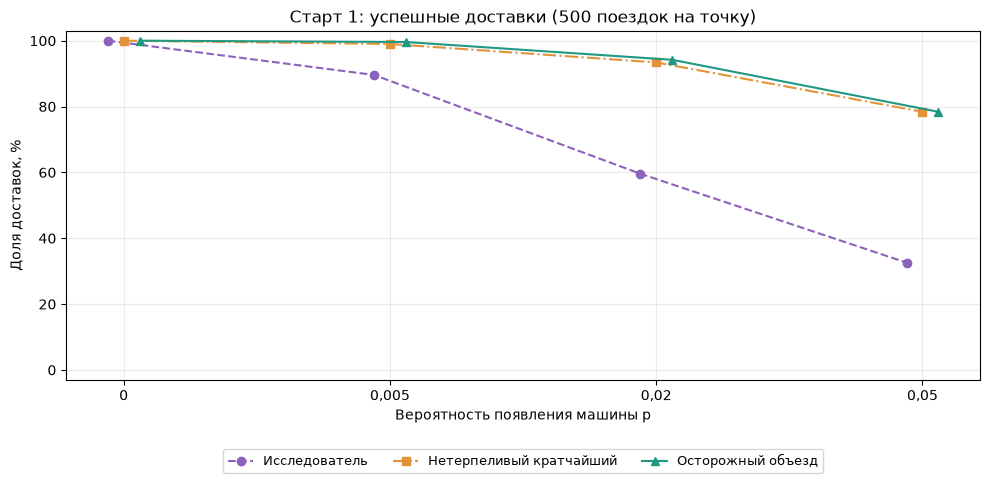

In [26]:
# Показываем успешные доставки для старта 1.
show_metric_plot(1, "success_percent", "успешные доставки", "Доля доставок, %")

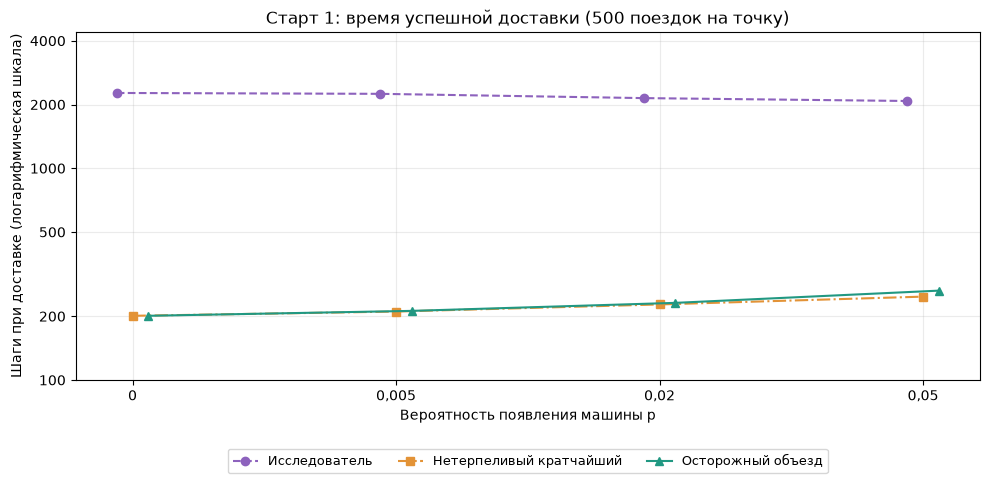

In [27]:
# Показываем время успешной доставки для старта 1.
show_metric_plot(1, "successful_steps", "время успешной доставки", "Шаги при доставке (логарифмическая шкала)")

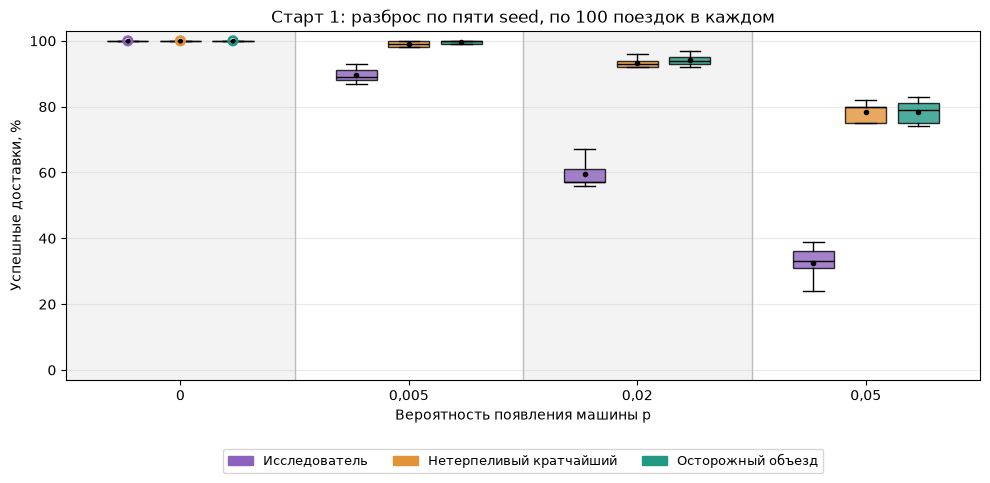

In [28]:
# Показываем разброс показателя по пяти seed.
show_boxplot(1, "success", 100, "Успешные доставки, %", "success_boxplot")

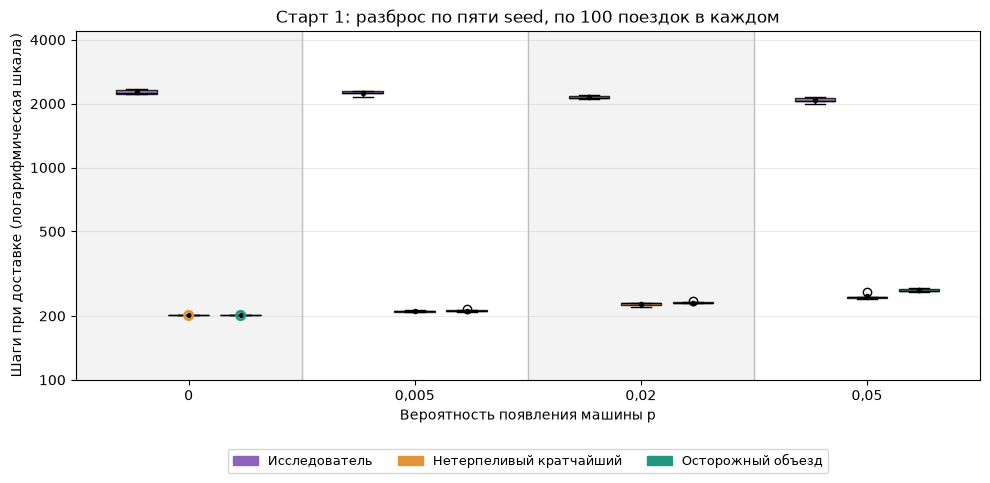

In [29]:
# Показываем разброс времени доставки по пяти seed для старта 1.
show_boxplot(1, "successful_steps", 1, "Шаги при доставке (логарифмическая шкала)", "steps_boxplot")

**Маршруты от старта 1, эпизод 211:** один поток машин и масштаб. Ниже каждая стратегия показана отдельно.

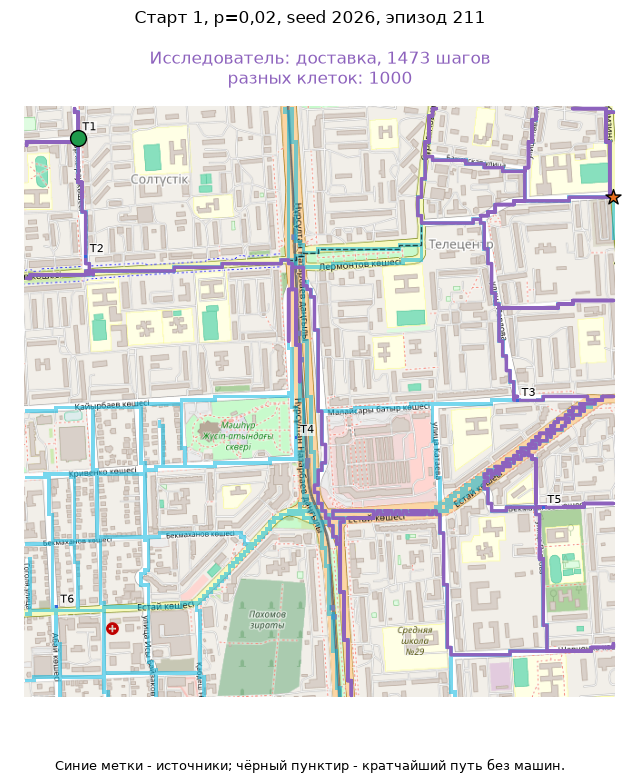

In [30]:
# Показываем исследователя для старта 1.
show_route_map(road_map, RESULTS_DIR, 0, 211, "explorer")

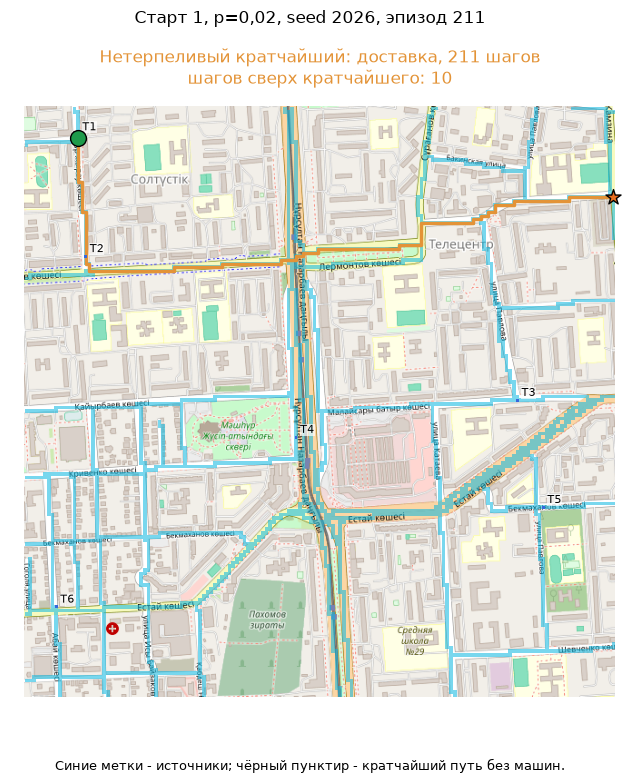

In [31]:
# Показываем shortest_path для старта 1.
show_route_map(road_map, RESULTS_DIR, 0, 211, "shortest_path")

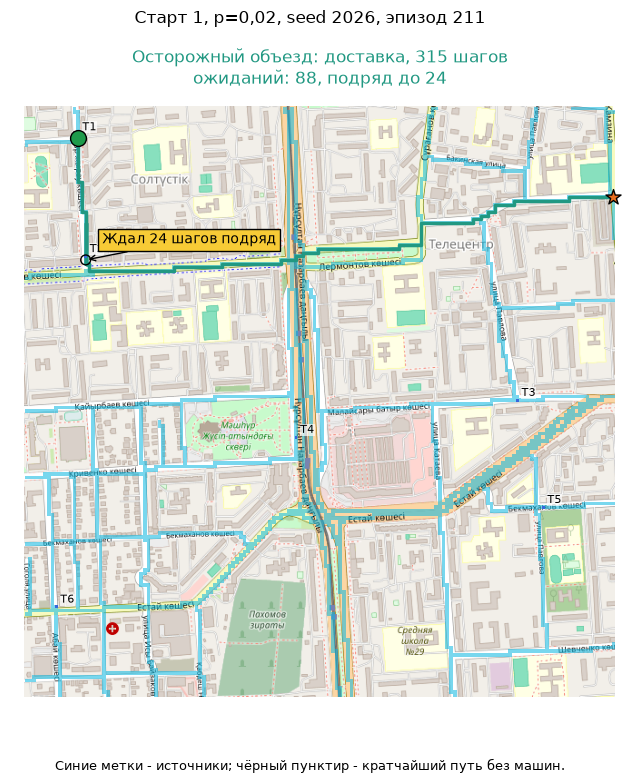

In [32]:
# Показываем traffic_aware для старта 1.
show_route_map(road_map, RESULTS_DIR, 0, 211, "traffic_aware")

### Старт 2

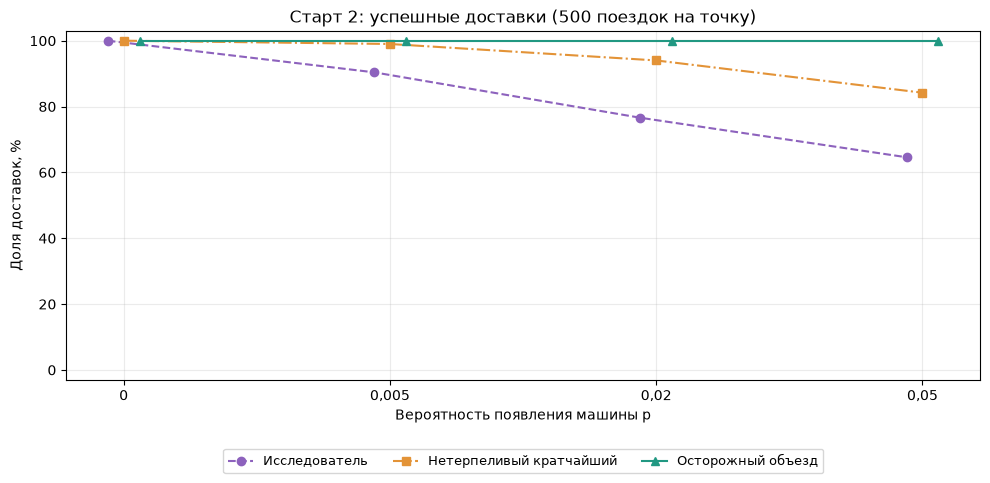

In [33]:
# Показываем успешные доставки для старта 2.
show_metric_plot(2, "success_percent", "успешные доставки", "Доля доставок, %")

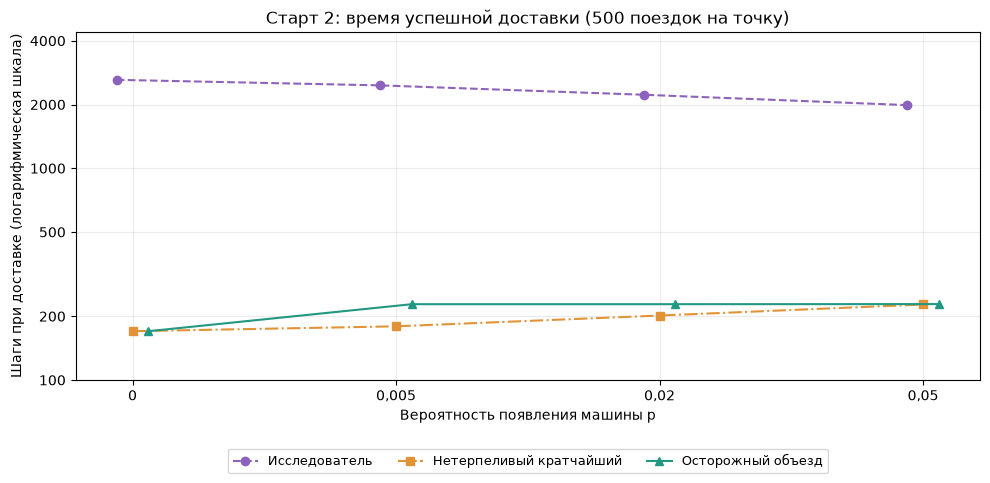

In [34]:
# Показываем время успешной доставки для старта 2.
show_metric_plot(2, "successful_steps", "время успешной доставки", "Шаги при доставке (логарифмическая шкала)")

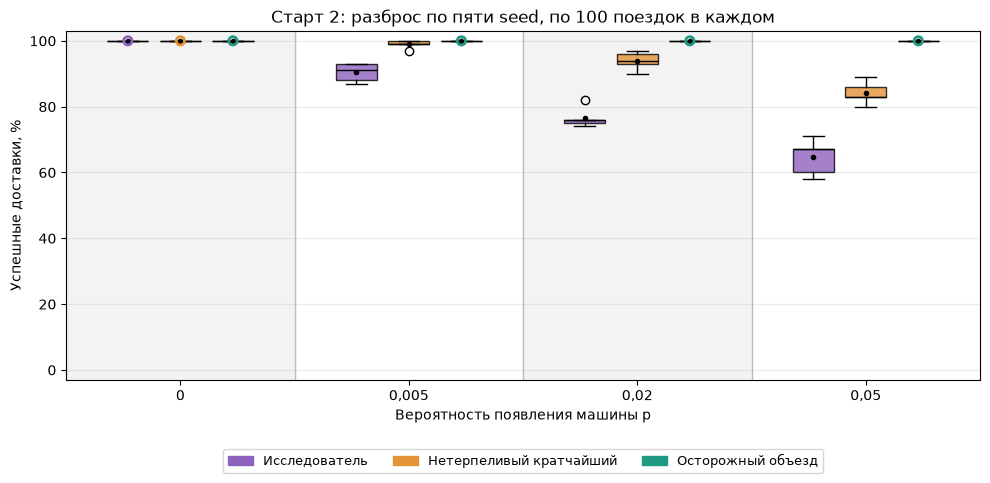

In [35]:
# Показываем разброс показателя по пяти seed.
show_boxplot(2, "success", 100, "Успешные доставки, %", "success_boxplot")

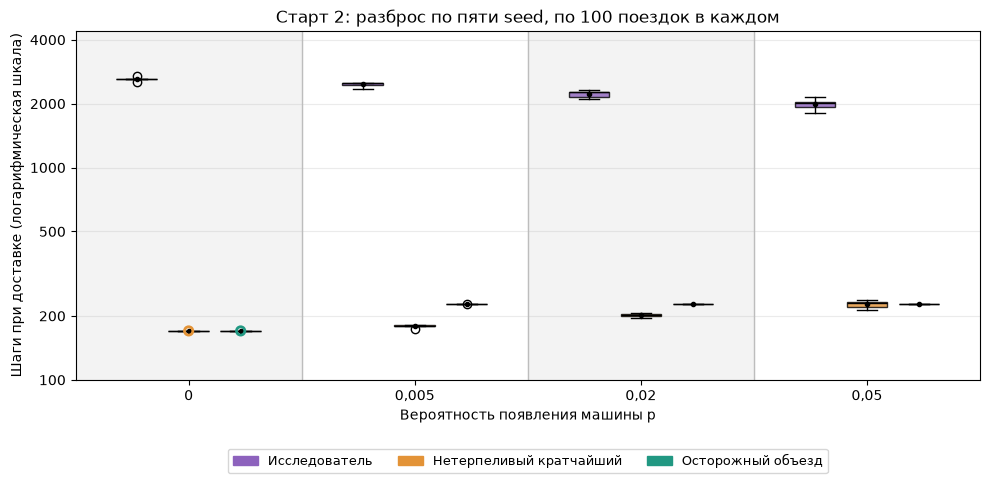

In [36]:
# Показываем разброс времени доставки по пяти seed для старта 2.
show_boxplot(2, "successful_steps", 1, "Шаги при доставке (логарифмическая шкала)", "steps_boxplot")

**Маршруты от старта 2, эпизод 97:** один поток машин и масштаб. Ниже каждая стратегия показана отдельно.

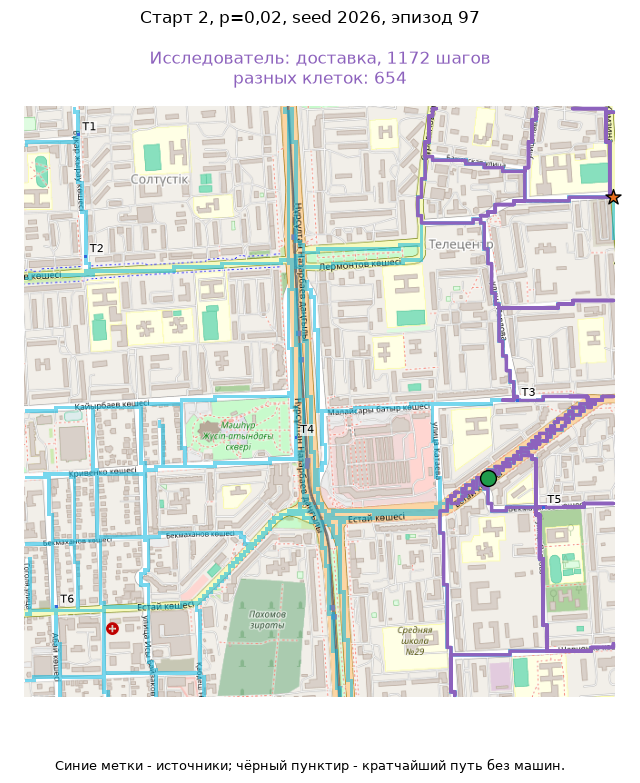

In [37]:
# Показываем исследователя для старта 2.
show_route_map(road_map, RESULTS_DIR, 1, 97, "explorer")

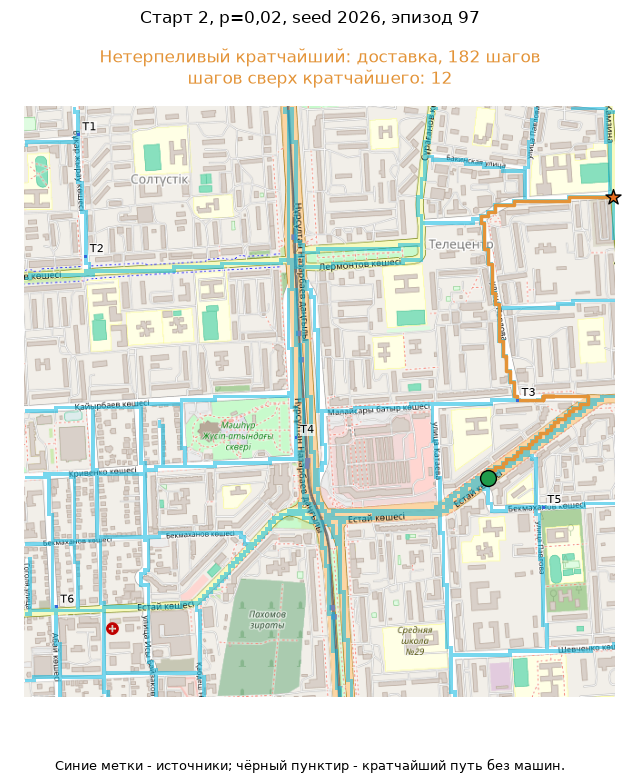

In [38]:
# Показываем shortest_path для старта 2.
show_route_map(road_map, RESULTS_DIR, 1, 97, "shortest_path")

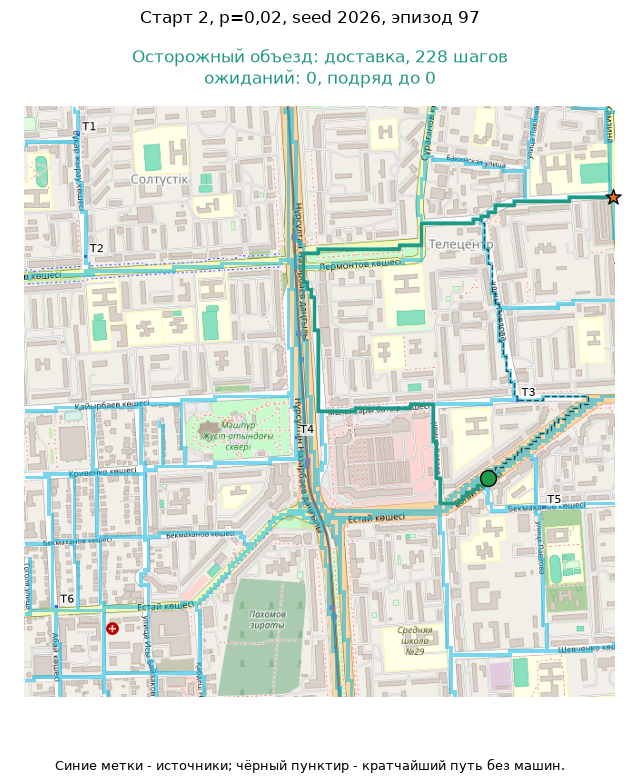

In [39]:
# Показываем traffic_aware для старта 2.
show_route_map(road_map, RESULTS_DIR, 1, 97, "traffic_aware")

### Старт 3

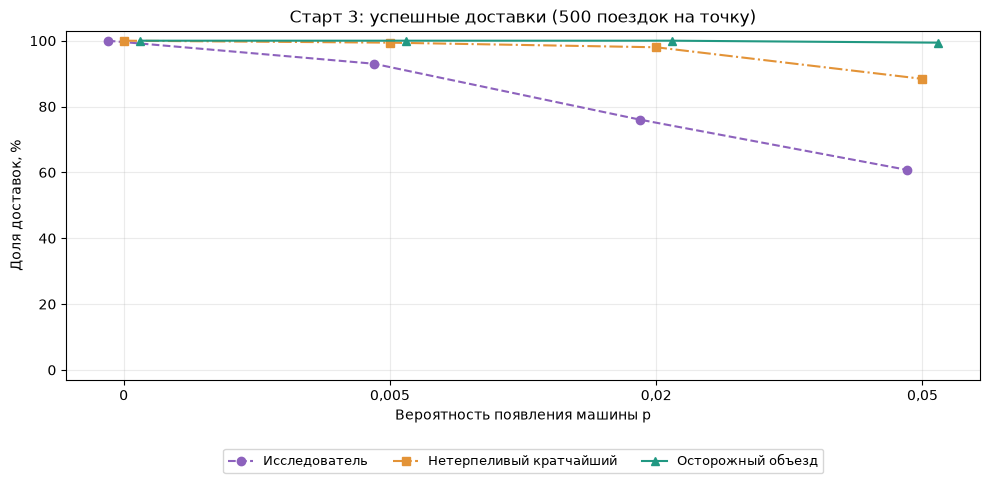

In [40]:
# Показываем успешные доставки для старта 3.
show_metric_plot(3, "success_percent", "успешные доставки", "Доля доставок, %")

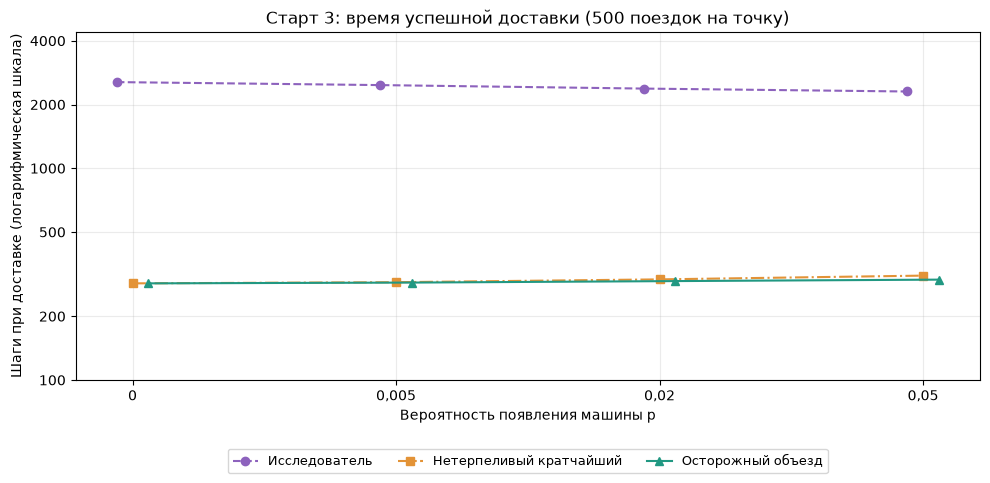

In [41]:
# Показываем время успешной доставки для старта 3.
show_metric_plot(3, "successful_steps", "время успешной доставки", "Шаги при доставке (логарифмическая шкала)")

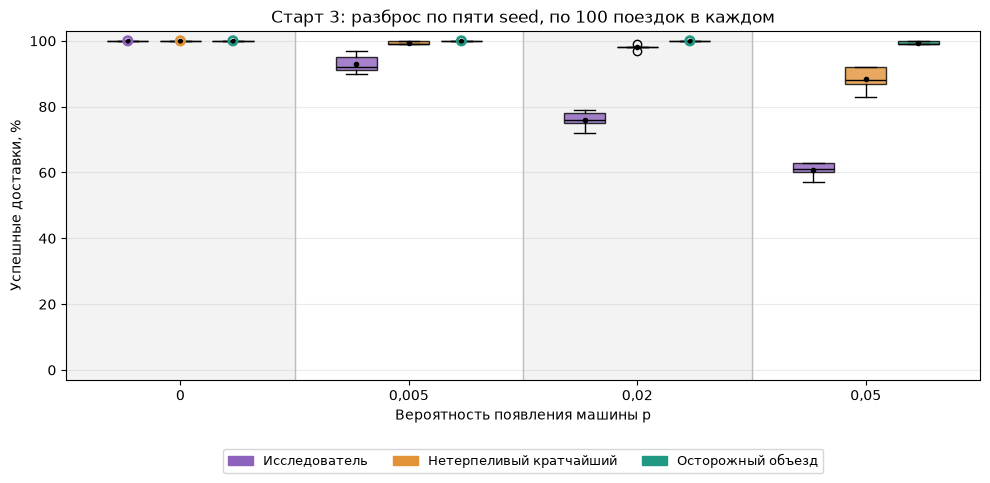

In [42]:
# Показываем разброс показателя по пяти seed.
show_boxplot(3, "success", 100, "Успешные доставки, %", "success_boxplot")

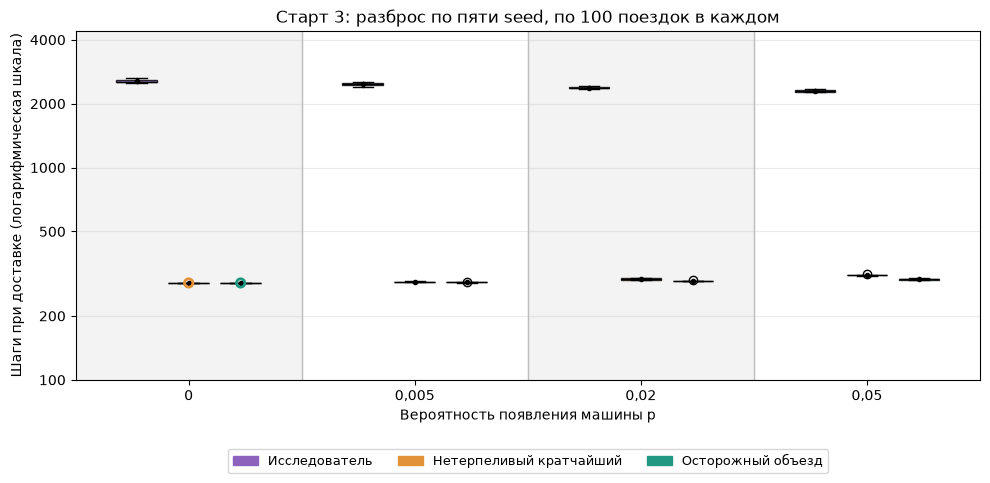

In [43]:
# Показываем разброс времени доставки по пяти seed для старта 3.
show_boxplot(3, "successful_steps", 1, "Шаги при доставке (логарифмическая шкала)", "steps_boxplot")

**Маршруты от старта 3, эпизод 47:** один поток машин и масштаб. Ниже каждая стратегия показана отдельно.

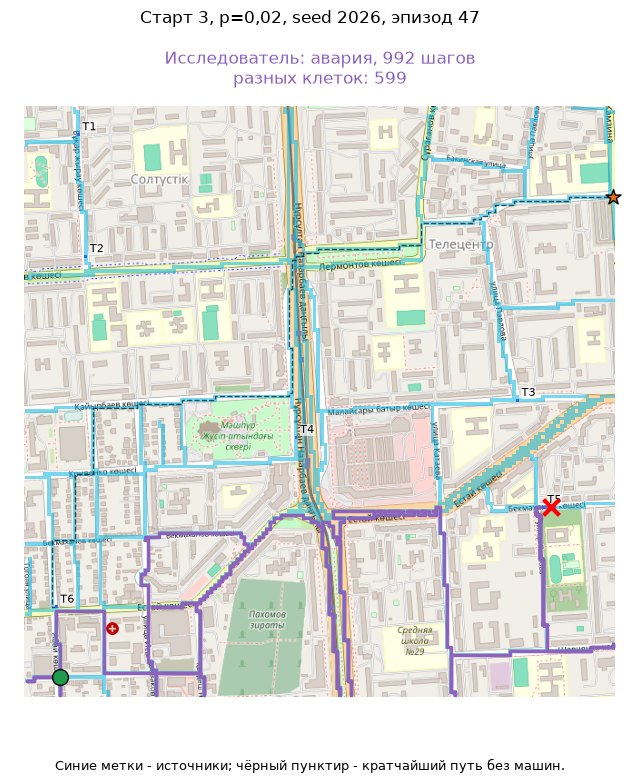

In [44]:
# Показываем исследователя для старта 3.
show_route_map(road_map, RESULTS_DIR, 2, 47, "explorer")

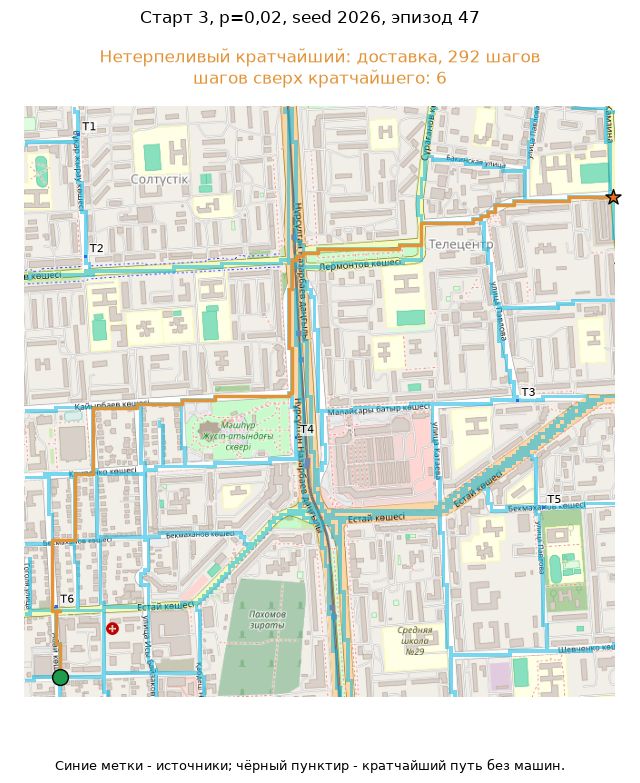

In [45]:
# Показываем shortest_path для старта 3.
show_route_map(road_map, RESULTS_DIR, 2, 47, "shortest_path")

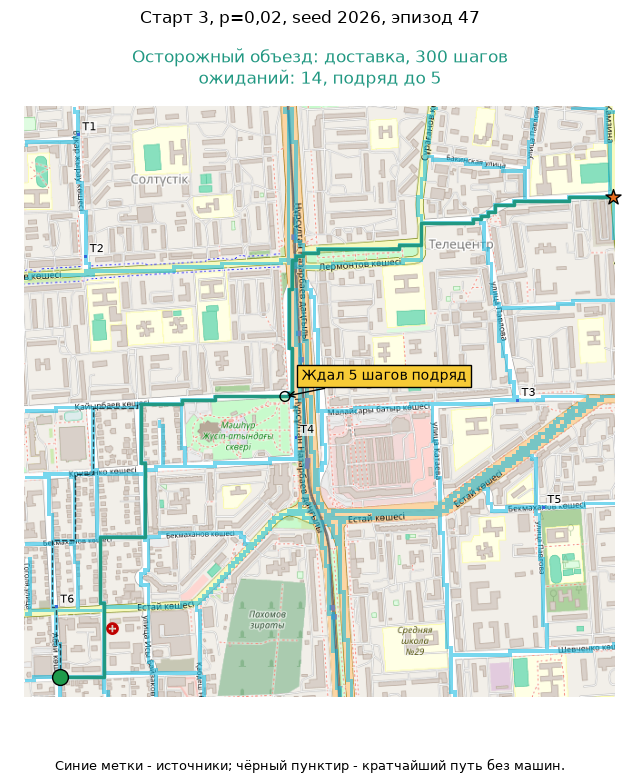

In [46]:
# Показываем traffic_aware для старта 3.
show_route_map(road_map, RESULTS_DIR, 2, 47, "traffic_aware")

### Сводная таблица при p = 0,02

Доля доставок рассчитана по всем 500 поездкам для каждого старта и стратегии. Шаги при успехе - среднее только по доставленным грузам. Меньше шагов означает быстрее.

In [47]:
# Берём уже рассчитанные показатели при p = 0.02.
report_table = condition_summary.reset_index()
report_table = report_table[report_table.rate == .02].copy()
report_table["policy"] = report_table.policy.replace(STRATEGY_NAMES)

# Оставляем нужные столбцы и задаём русские заголовки.
report_table = report_table[["start", "policy", "delivery_count", "episode_count",
                             "success_percent", "successful_steps"]]
report_table.columns = ["Старт", "Стратегия", "Доставки", "Всего поездок", "Успех, %",
                        "Шаги при успехе"]
display(report_table.round(2))

,Старт,Стратегия,Доставки,Всего поездок,"Успех, %",Шаги при успехе
2,1,Исследователь,298,500,59.6,2143.99
6,1,Нетерпеливый кратчайший,467,500,93.4,227.37
10,1,Осторожный объезд,471,500,94.2,231.35
14,2,Исследователь,383,500,76.6,2223.45
18,2,Нетерпеливый кратчайший,470,500,94.0,201.56
22,2,Осторожный объезд,500,500,100.0,228.03
26,3,Исследователь,380,500,76.0,2378.03
30,3,Нетерпеливый кратчайший,490,500,98.0,298.66
34,3,Осторожный объезд,500,500,100.0,293.15


## 8. Анимация поездок

Слева крупный план 40 x 40 клеток. Курьер и машины занимают ровно одну клетку.
Справа вся карта: зелёная точка - старт, оранжевая - цель, красная - курьер, рамка - область крупного плана.
Жёлтая линия показывает пройденный путь; под картой указаны строка и столбец курьера.

Источники Т1-Т6 видны в обоих видах: на крупном плане метка немного меньше клетки, на обзоре маленький квадрат в 2 пикселя изображения. Подписи расположены рядом.

Ниже показаны доставка и авария каждой стратегии при p = 0,02 и seed 2026. Примеры охватывают три старта и демонстрируют исследование, движение без ожидания, объезд и ожидание. Неудачи сохранены наравне с успехами.

Под картой показано фактическое решение перед следующим ходом. Жёлтая плашка выделяет остановку; счётчик показывает уже выполненные шаги ожидания. Красная рамка выделяет машину, влияющую на решение. У исследователя также видно число разных посещённых клеток.

### 8.1. Оформление кадров

Следующие функции только рисуют уже рассчитанные клетки, правила движения они не меняют.
`draw_cell_square` рисует одну клетку, `label_source` - рамку и подпись источника.
Для GIF используется общая палитра: отдельные оттенки серого сохраняют чёрный текст читаемым.

In [48]:
# Рисуем одну клетку карты квадратом нужного размера.
def draw_cell_square(image_draw, grid_cell, color, origin_x, origin_y, pixels_per_cell, view_origin=(0, 0), inset=0):
    # Переводим координаты клетки в положение её левого верхнего угла на рисунке.
    row, column = grid_cell
    left = origin_x + (column - view_origin[1]) * pixels_per_cell
    top = origin_y + (row - view_origin[0]) * pixels_per_cell

    # Метки машин занимают клетку; небольшой отступ уменьшает только метки источников.
    image_draw.rectangle((left + inset, top + inset, left + pixels_per_cell - 1 - inset, top + pixels_per_cell - 1 - inset),
                         fill=color, outline="black", width=1)

# Рисуем рамку и номер источника машин на клетке.
def label_source(image_draw, source_number, left, top, size, view_bounds, small_font):
    # Тонкая рамка внутри клетки остаётся видна, когда на источнике стоит машина.
    image_draw.rectangle((left, top, left + size - 1, top + size - 1),
                         outline="#3667dc", width=1)

    # Измеряем короткую подпись и удерживаем её внутри видимой области.
    label = f"Т{source_number}"
    label_width = image_draw.textbbox((0, 0), label, font=small_font)[2]
    label_x = min(left + size + 2, view_bounds[2] - label_width - 2)
    label_y = max(view_bounds[1] + 1, min(top - 10, view_bounds[3] - 15))

    # Белая обводка текста заменяет большую плашку, закрывавшую дорогу.
    image_draw.text((label_x, label_y), label, font=small_font, fill="black",
                    stroke_width=1, stroke_fill="white")

In [49]:
# Переводит кадр в палитру GIF, сохраняя нейтральный цвет текста.
def prepare_gif_frame(frame_image, gif_palette):

    # По первому кадру создаём общую палитру, которую используем во всей анимации.
    if gif_palette is None:
        # Карте - 96 цветов, тексту - 24 оттенка серого, меткам - свои цвета.
        gif_palette = frame_image.quantize(colors=96)
        marker_colors = ("#000000", "#ffffff", "#ed243c", "#914fc1",
                         "#1e9b4b", "#e96f1f", "#3667dc", "#f7cb36")
        palette_values = gif_palette.getpalette()

        # Добавляем 24 оттенка серого; каждый цвет записан тремя числами RGB.
        gray_colors = []
        # У серого цвета одинаковые красная, зелёная и синяя составляющие.
        for shade in np.linspace(0, 255, 24).round():
            gray_colors.extend([int(shade), int(shade), int(shade)])
        palette_values[96 * 3:120 * 3] = gray_colors

        # Резервируем точные цвета для курьера, машин, меток и следа пути.
        for palette_index, color in enumerate(marker_colors, 120):
            # Pillow переводит запись цвета в три числа RGB.
            palette_values[palette_index * 3:palette_index * 3 + 3] = ImageColor.getrgb(color)
        gif_palette.putpalette(palette_values)
    palette_values = gif_palette.getpalette()

    # Переводим кадр в общую палитру без точечного смешивания цветов.
    gif_frame = frame_image.quantize(palette=gif_palette, dither=PILImage.Dither.NONE)
    # Не даём палитре карты окрашивать сглаженные края чёрных букв.
    frame_colors = np.asarray(frame_image)
    neutral_pixels = ((frame_colors[:, :, 0] == frame_colors[:, :, 1])
                      & (frame_colors[:, :, 1] == frame_colors[:, :, 2]))

    # Для серых пикселей явно выбираем серые цвета палитры, сохраняя текст нейтральным.
    color_indices = np.asarray(gif_frame).copy()
    gray_values = frame_colors[:, :, 0][neutral_pixels]
    gray_indices = np.rint(gray_values * (23 / 255)).astype("uint8")
    color_indices[neutral_pixels] = 96 + gray_indices

    # Собираем кадр из номеров цветов и возвращаем его вместе с общей палитрой.
    gif_frame = PILImage.fromarray(color_indices)
    gif_frame.putpalette(palette_values)
    return gif_frame, gif_palette

### 8.2. Создание GIF

На каждом кадре рисуем подложку, дороги, след пути, старт, цель, источники, машины и курьера.
Окно крупного плана сдвигается, когда курьер приближается к краю; справа остаётся общий вид.
У каждого кадра непрозрачный фон, а палитра одинакова во всём GIF.

In [50]:
# Показывает один эпизод: крупный план и обзор всей карты.
def save_episode_gif(road_map, output_dir, output_name, start_index, spawn_probability, episode_index, strategy):

    # Запускаем выбранную поездку с записью всех положений курьера и машин.
    probability_index = SPAWN_PROBABILITIES.index(spawn_probability)
    episode_result = run_episode(
        road_map, start_index, spawn_probability,
        make_episode_seed(2026, probability_index, start_index, episode_index, 0),
        make_episode_seed(2026, probability_index, start_index, episode_index, STRATEGIES.index(strategy) + 1),
        strategy, MAX_EPISODE_STEPS, record=True)

    # Загружаем подложку и метки источников; полосу подписи исключаем из размеров карты.
    osm_basemap = PILImage.open("data/source_osm_map.png").convert("RGB")
    map_width, map_height = osm_basemap.size
    cells_per_side = road_map.passable_cells.shape[0]
    source_cells = road_map.traffic_sources
    # Размер модели не меняется: 40 клеток увеличиваем до 640 экранных пикселей.
    view_cells, cell_pixels = 40, 16
    zoom_pixels = view_cells * cell_pixels
    zoom_x, zoom_y = 20, 42
    overview_x, overview_y, overview_pixels = 690, 72, 300

    # Подготавливаем списки пройденных клеток и готовых кадров.
    courier_route = []
    gif_frames = []
    gif_palette = None
    total_waits = 0
    waiting_streak = 0
    visited_cells = set()

    # Загружаем обычный и уменьшенный шрифты для подписей на кадре.
    font_path = font_manager.findfont("DejaVu Sans")
    font = ImageFont.truetype(font_path, 16)
    small_font = ImageFont.truetype(font_path, 14)
    source_font = ImageFont.truetype(font_path, 11)
    decision_font = ImageFont.truetype(font_path, 20)

    # Готовим неизменяемый обзор всей карты: осветляем фон и накладываем дорожные клетки.
    overview_map = osm_basemap.crop((0, 0, map_width, map_height)).resize((overview_pixels, overview_pixels))
    overview_map = PILImage.blend(overview_map, PILImage.new("RGB", overview_map.size, "white"), .18)
    overview_road_mask = PILImage.fromarray((road_map.passable_cells * 95).astype("uint8"))
    overview_road_mask = overview_road_mask.resize(overview_map.size, PILImage.Resampling.NEAREST)
    overview_map.paste((20, 185, 225), (0, 0), overview_road_mask)

    # Ставим окно крупного плана около старта и удерживаем его внутри карты.
    view_top_row = max(0, min(cells_per_side - view_cells, road_map.start_cells[start_index][0] - view_cells // 2))
    view_left_column = max(0, min(cells_per_side - view_cells, road_map.start_cells[start_index][1] - view_cells // 2))

    # Сдвигаем окно, когда до его края остаётся меньше восьми клеток.
    def follow_coordinate(position, window_start):
        if position < window_start + 8:
            window_start = position - 8
        elif position > window_start + view_cells - 9:
            window_start = position - view_cells + 9
        return max(0, min(cells_per_side - view_cells, window_start))

    # Для каждого сохранённого шага собираем один кадр анимации.
    for frame_number, (courier_cell, car_cells) in enumerate(episode_result["frames"]):
        courier_route.append(courier_cell)
        visited_cells.add(courier_cell)
        decision = episode_result["decisions"][frame_number]

        # Считаем уже выполненные остановки, включая подряд идущие шаги ожидания.
        if frame_number > 0:
            if episode_result["decisions"][frame_number - 1]["action"] == "stop":
                total_waits += 1
                waiting_streak += 1
            else:
                waiting_streak = 0
        # Сдвигаем окно лишь тогда, когда курьер подходит к его краю.
        # Оставляем запас 8 клеток до края окна и не выходим за пределы карты.
        view_top_row = follow_coordinate(courier_cell[0], view_top_row)
        view_left_column = follow_coordinate(courier_cell[1], view_left_column)

        # Переводим границы текущего окна из клеток в пиксели исходной подложки.
        crop_box = (round(view_left_column / cells_per_side * map_width),
                    round(view_top_row / cells_per_side * map_height),
                    round((view_left_column + view_cells) / cells_per_side * map_width),
                    round((view_top_row + view_cells) / cells_per_side * map_height))

        # Вырезаем крупный план, увеличиваем его и осветляем фон для заметности клеток.
        zoomed_basemap = osm_basemap.crop(crop_box).resize((zoom_pixels, zoom_pixels), PILImage.Resampling.BICUBIC)
        zoomed_basemap = PILImage.blend(
            zoomed_basemap, PILImage.new("RGB", zoomed_basemap.size, "white"), .32)
        # Бирюзовые квадраты - проходимые клетки поверх осветлённой подложки OSM.
        zoom_road_mask = PILImage.fromarray((
            road_map.passable_cells[
                view_top_row:view_top_row + view_cells,
                view_left_column:view_left_column + view_cells] * 150).astype("uint8"))
        zoomed_basemap.paste(
            (20, 185, 225), (0, 0),
            zoom_road_mask.resize(zoomed_basemap.size, PILImage.Resampling.NEAREST))

        # Создаём белый фон кадра и размещаем крупный план слева, обзор справа.
        frame_image = PILImage.new("RGB", (1010, 820), "white")
        frame_image.paste(zoomed_basemap, (zoom_x, zoom_y))
        frame_image.paste(overview_map, (overview_x, overview_y))
        image_draw = ImageDraw.Draw(frame_image)

        # Добавляем исход поездки в заголовок только на последнем кадре.
        outcome_labels = {"success": "Доставка!", "collision": "Авария!", "timeout": "Лимит шагов"}
        outcome_suffix = ""
        if frame_number == episode_result["steps"]:
            outcome_suffix = " | " + outcome_labels[episode_result["outcome"]]
        image_draw.text(
            (20, 12),
            f"Шаг {frame_number}/{episode_result['steps']} | {STRATEGY_NAMES[strategy]} | "
            f"p = {str(spawn_probability).replace('.', ',')}{outcome_suffix}",
            font=font, fill="black")

        # Подписываем обзор карты и задаём проверку попадания клетки в крупный план.
        image_draw.text((690, 42), "Вся карта", font=font, fill="black")
        # Проверяем, попала ли клетка в крупный план.
        def in_zoom_view(grid_cell):
            row, column = grid_cell
            row_visible = view_top_row <= row < view_top_row + view_cells
            column_visible = view_left_column <= column < view_left_column + view_cells
            return row_visible and column_visible
        # След пути лежит под цветными квадратами курьера, машин и цели.
        # Рисуем только соседние точки пути, которые обе попали в окно.
        for previous_cell, route_cell in zip(courier_route, courier_route[1:]):
            if in_zoom_view(previous_cell) and in_zoom_view(route_cell):
                route_segment = [
                    (zoom_x + (column - view_left_column + .5) * cell_pixels,
                     zoom_y + (row - view_top_row + .5) * cell_pixels)
                    for row, column in (previous_cell, route_cell)]
                image_draw.line(route_segment, fill="#f7cb36", width=4)

        # Рисуем старты, попавшие в крупный план.
        for start_cell in road_map.start_cells:
            if in_zoom_view(start_cell):
                draw_cell_square(image_draw, start_cell, "#1e9b4b", zoom_x, zoom_y,
                                 cell_pixels, (view_top_row, view_left_column))

        # Рисуем источники внутри их клетки с отступом в один пиксель изображения.
        for traffic_source in source_cells:
            if in_zoom_view(traffic_source):
                draw_cell_square(image_draw, traffic_source, "#3667dc", zoom_x, zoom_y,
                                 cell_pixels, (view_top_row, view_left_column), inset=1)

        # Рисуем цель, если она попадает в текущее окно.
        if in_zoom_view(road_map.goal_cell):
            draw_cell_square(image_draw, road_map.goal_cell, "#e96f1f", zoom_x, zoom_y,
                             cell_pixels, (view_top_row, view_left_column))

        # Рисуем каждую машину, попавшую в крупный план.
        for car_cell in car_cells:
            if in_zoom_view(car_cell):
                draw_cell_square(image_draw, car_cell, "#914fc1", zoom_x, zoom_y,
                                 cell_pixels, (view_top_row, view_left_column))

        # Выделяем машину, которая влияет на текущее решение стратегии.
        if decision["car"] is not None and in_zoom_view(decision["car"]):
            car_row, car_column = decision["car"]
            car_x = zoom_x + (car_column - view_left_column) * cell_pixels
            car_y = zoom_y + (car_row - view_top_row) * cell_pixels
            image_draw.rectangle((car_x - 2, car_y - 2, car_x + cell_pixels + 1, car_y + cell_pixels + 1),
                                 outline="#ed243c", width=2)

        # Рисуем курьера поверх остальных объектов и выделяем его жёлтой рамкой.
        draw_cell_square(image_draw, courier_cell, "#ed243c", zoom_x, zoom_y,
                         cell_pixels, (view_top_row, view_left_column))
        courier_x = zoom_x + (courier_cell[1] - view_left_column) * cell_pixels
        courier_y = zoom_y + (courier_cell[0] - view_top_row) * cell_pixels

        # Обводим курьера жёлтой рамкой, чтобы он не терялся на фоне дороги.
        image_draw.rectangle(
            (courier_x - 2, courier_y - 2, courier_x + cell_pixels + 1, courier_y + cell_pixels + 1),
            outline="#ffdb37", width=3)

        # После машин восстанавливаем видимые рамки и подписи источников.
        for source_number, traffic_source in enumerate(source_cells, 1):
            if in_zoom_view(traffic_source):
                source_x = zoom_x + (traffic_source[1] - view_left_column) * cell_pixels
                source_y = zoom_y + (traffic_source[0] - view_top_row) * cell_pixels
                label_source(image_draw, source_number, source_x + 1, source_y + 1, cell_pixels - 2,
                             (zoom_x, zoom_y, zoom_x + zoom_pixels, zoom_y + zoom_pixels), source_font)

        # Переводим весь пройденный путь в координаты маленькой обзорной карты.
        overview_route_pixels = [
            (overview_x + (column + .5) / cells_per_side * overview_pixels,
             overview_y + (row + .5) / cells_per_side * overview_pixels)
            for row, column in courier_route]
        if len(overview_route_pixels) > 1:
            image_draw.line(overview_route_pixels, fill="#f7cb36", width=3, joint="curve")

        # На обзоре показываем все источники с номерами, даже если они вне крупного плана.
        for source_number, (row, column) in enumerate(source_cells, 1):
            source_size = 2
            source_x = round(overview_x + (column + .5) / cells_per_side * overview_pixels - source_size / 2)
            source_y = round(overview_y + (row + .5) / cells_per_side * overview_pixels - source_size / 2)
            image_draw.rectangle((source_x, source_y, source_x + source_size - 1,
                                  source_y + source_size - 1), fill="#3667dc")
            label_source(image_draw, source_number, source_x, source_y, source_size,
                         (overview_x, overview_y, overview_x + overview_pixels,
                          overview_y + overview_pixels), source_font)

        # Отмечаем на обзоре выбранный старт, цель и текущее положение курьера.
        for marker_cell, color in [(road_map.start_cells[start_index], "#1e9b4b"),
                                   (road_map.goal_cell, "#e96f1f"), (courier_cell, "#ed243c")]:
            marker_x = overview_x + (marker_cell[1] + .5) / cells_per_side * overview_pixels
            marker_y = overview_y + (marker_cell[0] + .5) / cells_per_side * overview_pixels
            image_draw.ellipse(
                (marker_x - 6, marker_y - 6, marker_x + 6, marker_y + 6),
                fill=color, outline="black", width=2)

        # Рисуем на обзоре прямоугольник, соответствующий области крупного плана.
        image_draw.rectangle(
            (overview_x + view_left_column / cells_per_side * overview_pixels,
             overview_y + view_top_row / cells_per_side * overview_pixels,
             overview_x + (view_left_column + view_cells) / cells_per_side * overview_pixels,
             overview_y + (view_top_row + view_cells) / cells_per_side * overview_pixels),
            outline="black", width=2)

        # Под обзором показываем координаты курьера, расстояние до цели и число машин.
        image_draw.text((690, 390), f"Курьер: строка {courier_cell[0]}, столбец {courier_cell[1]}",
                        font=small_font, fill="black")
        image_draw.text((690, 415), f"До цели: {road_map.distance_to_goal[courier_cell]} клеток",
                        font=small_font, fill="black")
        image_draw.text((690, 440), f"Машин: {len(car_cells)}", font=small_font, fill="black")

        # Рисуем легенду: для каждого объекта цветной квадрат и его название.
        for legend_index, (color, label) in enumerate((("#ed243c", "Курьер"), ("#914fc1", "Машины"),
                                                       ("#1e9b4b", "Старт"), ("#e96f1f", "Цель"),
                                                       ("#3667dc", "Т1-Т6: источники машин"),
                                                       ("#f7cb36", "Пройденный путь"))):
            legend_y = 485 + 27 * legend_index
            image_draw.rectangle((690, legend_y, 706, legend_y + 16), fill=color, outline="black")
            image_draw.text((715, legend_y - 1), label, font=small_font, fill="black")
        # Под картой явно показываем решение; жёлтая плашка означает остановку.
        banner_color = "white"
        if decision["action"] == "stop":
            banner_color = "#f7cb36"
        image_draw.rectangle((20, 686, 990, 727), fill=banner_color, outline="black", width=2)
        image_draw.text((32, 696), decision["note"], font=decision_font, fill="black")
        image_draw.text((20, 741),
                        f"Ожидание: {total_waits} шагов | Подряд: {waiting_streak} | "
                        f"Посещено разных клеток: {len(visited_cells)}", font=font, fill="black")
        image_draw.text((20, 770), "Подпись объясняет решение перед следующим ходом.",
                        font=small_font, fill="black")
        image_draw.text((690, 660), "Красная рамка: выбранная машина", font=small_font, fill="black")
        image_draw.text(
            (20, 803), "Крупный план: 40 x 40 клеток, источник отмечен внутри клетки",
            font=small_font, fill="black")

        # Сохраняем средний кадр отдельной картинкой для быстрого просмотра.
        if frame_number == episode_result["steps"] // 2:
            frame_image.save(output_dir / f"{output_name}_preview.png")

        # Переводим кадр в палитру GIF и добавляем его в список анимации.
        gif_frame, gif_palette = prepare_gif_frame(frame_image, gif_palette)
        gif_frames.append(gif_frame)

    # Сохраняем полную поездку под понятным постоянным именем.
    gif_path = output_dir / f"{output_name}.gif"
    gif_frames[0].save(gif_path, save_all=True,
                       append_images=gif_frames[1:], duration=100, loop=0,
                       optimize=False, disposal=2)

    # Сообщаем исход поездки и возвращаем путь для показа в ноутбуке.
    print(f"{output_name}: {OUTCOME_NAMES[episode_result['outcome']]}, {episode_result['steps']} шагов", flush=True)
    return gif_path

### 8.3. Удачные и неудачные поездки

В каждой записи ниже: имя GIF, индекс старта (с нуля), `p`, номер эпизода, стратегия.
Успешные поездки со старта 2 в эпизоде 97 сравнивают три стратегии при одном потоке машин.
Дополнительный пример показывает ожидание осторожной стратегии. Эти поездки не заменяют массовый эксперимент.

In [51]:
# Фиксированные примеры: имя, индекс старта, вероятность трафика, эпизод, стратегия.
ANIMATION_EXAMPLES = (
    ("cautious_start2_detour_success", 1, .02, 97, "traffic_aware"),
    ("cautious_start3_wait_success", 2, .02, 150, "traffic_aware"),
    ("cautious_start1_collision", 0, .02, 213, "traffic_aware"),
    ("shortest_start2_success", 1, .02, 97, "shortest_path"),
    ("shortest_start1_collision", 0, .02, 84, "shortest_path"),
    ("explorer_start2_success", 1, .02, 97, "explorer"),
    ("explorer_start3_collision", 2, .02, 47, "explorer"),
)

# Сохраняем объезд, ожидание и по успеху и аварии каждой стратегии.
animation_paths = {}
for example in ANIMATION_EXAMPLES:
    animation_paths[example[0]] = save_episode_gif(road_map, RESULTS_DIR, *example)

cautious_start2_detour_success: доставка, 228 шагов


cautious_start3_wait_success: доставка, 349 шагов


cautious_start1_collision: авария, 85 шагов


shortest_start2_success: доставка, 182 шагов


shortest_start1_collision: авария, 82 шагов


explorer_start2_success: доставка, 1172 шагов


explorer_start3_collision: авария, 992 шагов


### Осторожный объезд: ожидание и доставка со старта 3 (эпизод 150)

На шагах 148–186 курьер ждёт 39 шагов подряд. Всего за поездку он ждёт 61 шаг и доставляет груз за 349 шагов. Ниже — полная поездка.

C:\UniProjects\rl-uni\results\cautious_start3_wait_success.gif

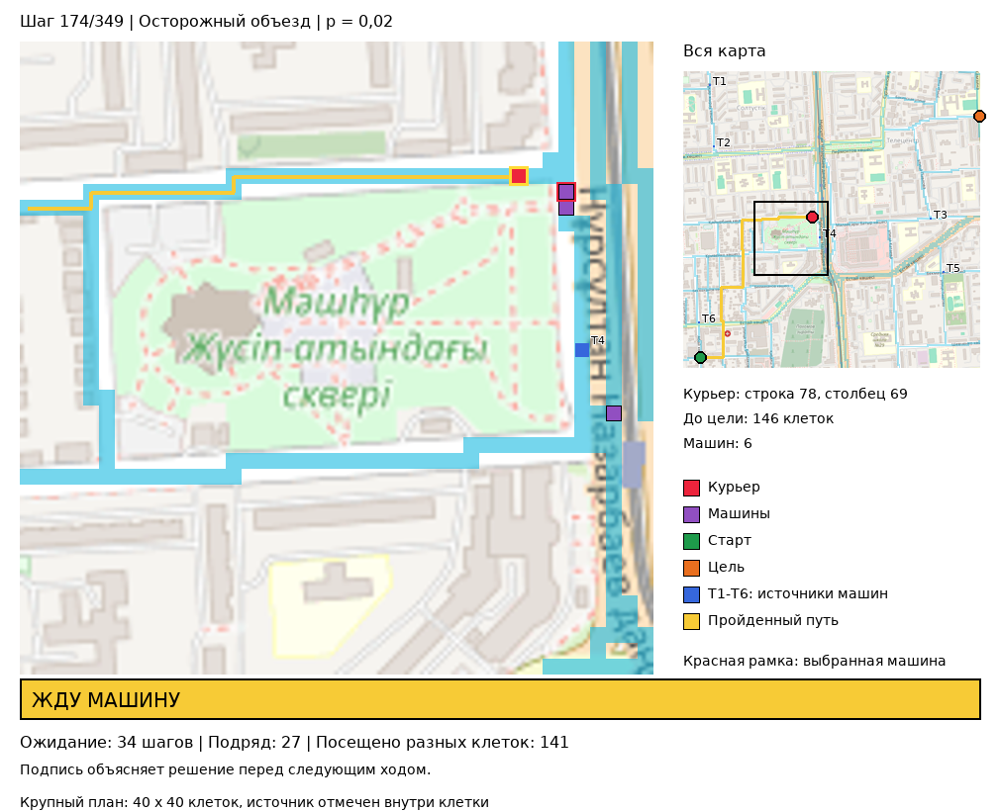

In [52]:
# Показываем кадр поездки и ссылку на полный GIF.
display(FileLink(animation_paths["cautious_start3_wait_success"].as_posix()))
display(Image(filename=str(RESULTS_DIR / "cautious_start3_wait_success_preview.png")))

### Осторожный объезд: авария со старта 1 (эпизод 213)

Курьер ждёт 47 шагов, из них 39 подряд, но на шаге 85 попадает в аварию.

C:\UniProjects\rl-uni\results\cautious_start1_collision.gif

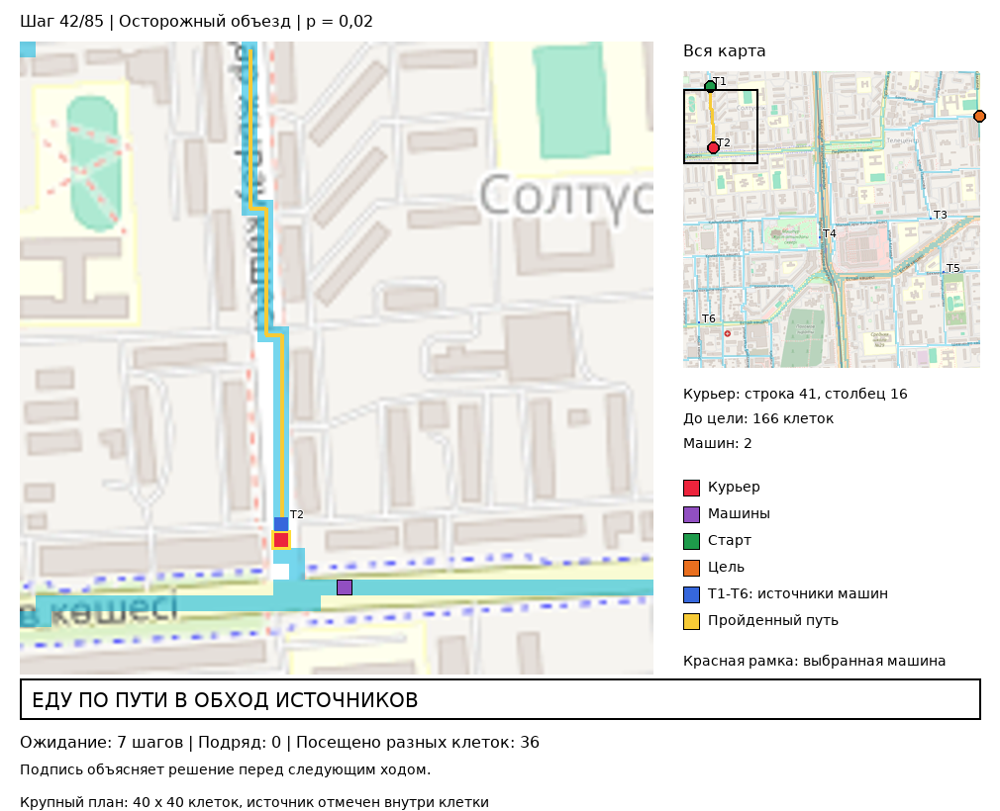

In [53]:
# Показываем кадр поездки и ссылку на полный GIF.
display(FileLink(animation_paths["cautious_start1_collision"].as_posix()))
display(Image(filename=str(RESULTS_DIR / "cautious_start1_collision_preview.png")))

### Нетерпеливый кратчайший: доставка со старта 2 (эпизод 97)

Доставка за 182 шага без ожидания. Подпись "НЕ ЖДУ" появляется рядом с машиной.

C:\UniProjects\rl-uni\results\shortest_start2_success.gif

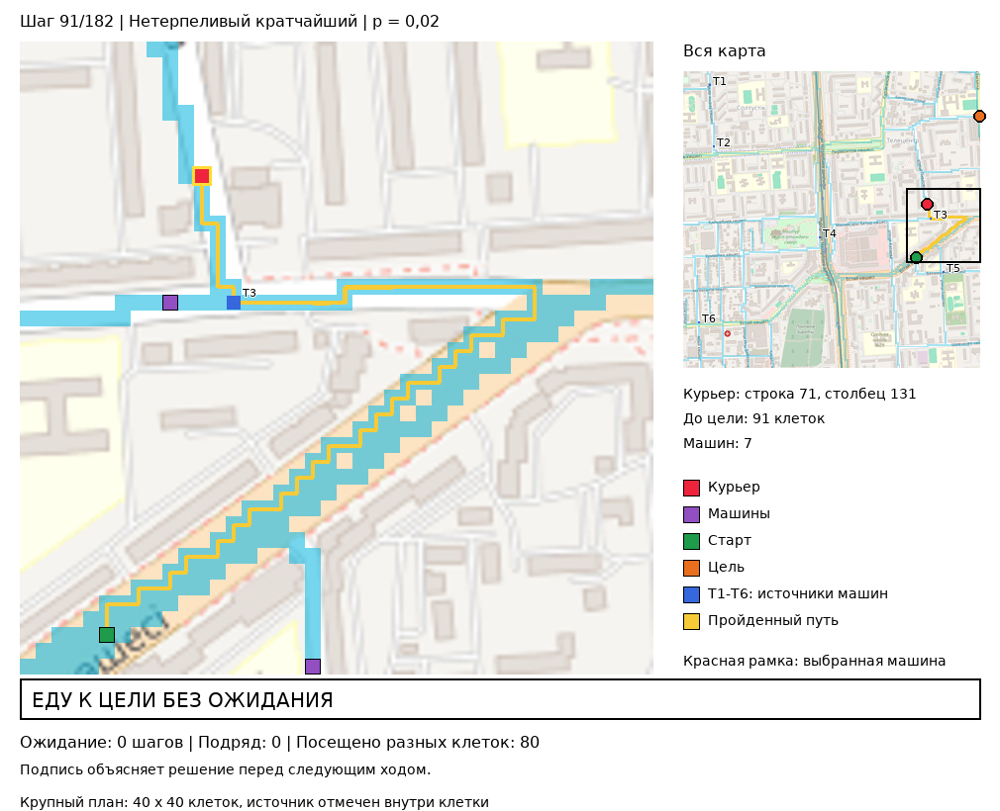

In [54]:
# Показываем кадр поездки и ссылку на полный GIF.
display(FileLink(animation_paths["shortest_start2_success"].as_posix()))
display(Image(filename=str(RESULTS_DIR / "shortest_start2_success_preview.png")))

### Нетерпеливый кратчайший: авария со старта 1 (эпизод 84)

До аварии выполнено 82 шага без остановок.

C:\UniProjects\rl-uni\results\shortest_start1_collision.gif

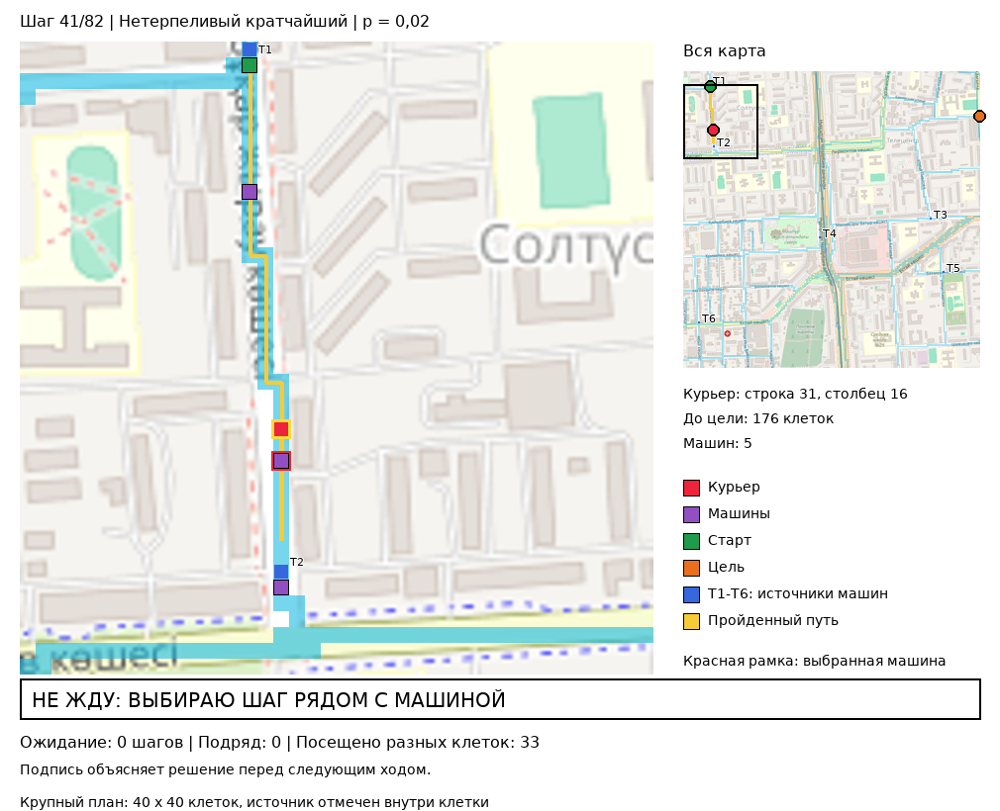

In [55]:
# Показываем кадр поездки и ссылку на полный GIF.
display(FileLink(animation_paths["shortest_start1_collision"].as_posix()))
display(Image(filename=str(RESULTS_DIR / "shortest_start1_collision_preview.png")))

### Исследователь: доставка со старта 2 (эпизод 97)

За 1172 шага посещает 654 разные клетки, исследует новые участки и отступает от машин.

C:\UniProjects\rl-uni\results\explorer_start2_success.gif

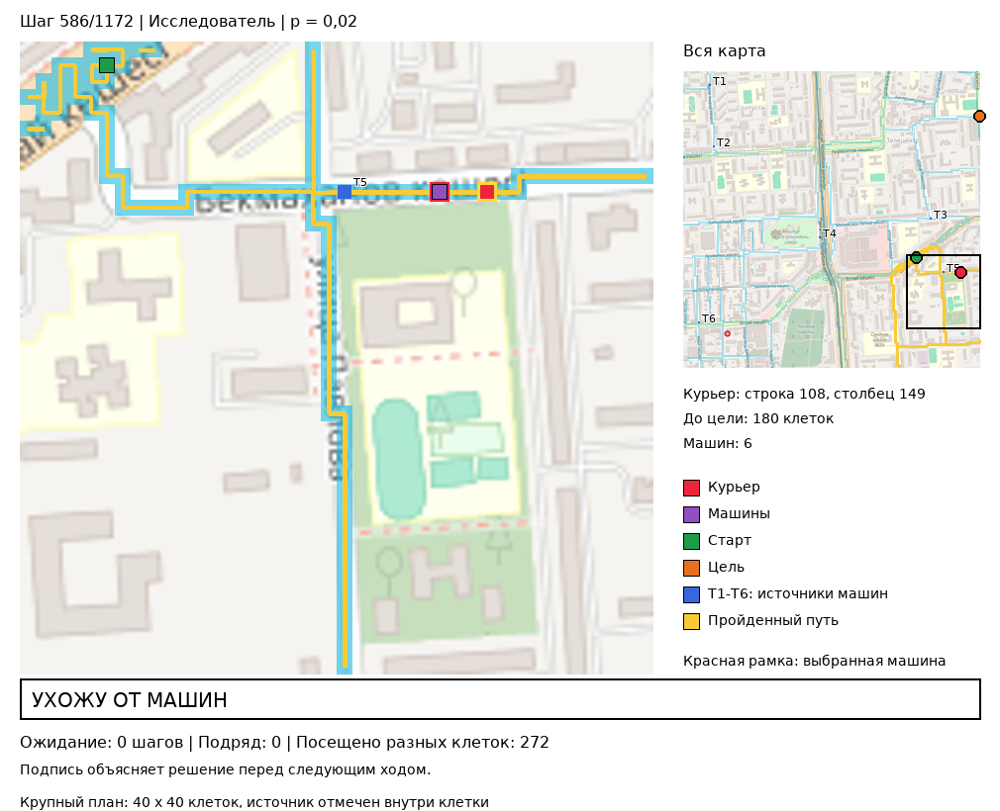

In [56]:
# Показываем кадр поездки и ссылку на полный GIF.
display(FileLink(animation_paths["explorer_start2_success"].as_posix()))
display(Image(filename=str(RESULTS_DIR / "explorer_start2_success_preview.png")))

### Исследователь: авария со старта 3 (эпизод 47)

До аварии на шаге 992 посещает 599 разных клеток. Видны попытки уйти от машин.

C:\UniProjects\rl-uni\results\explorer_start3_collision.gif

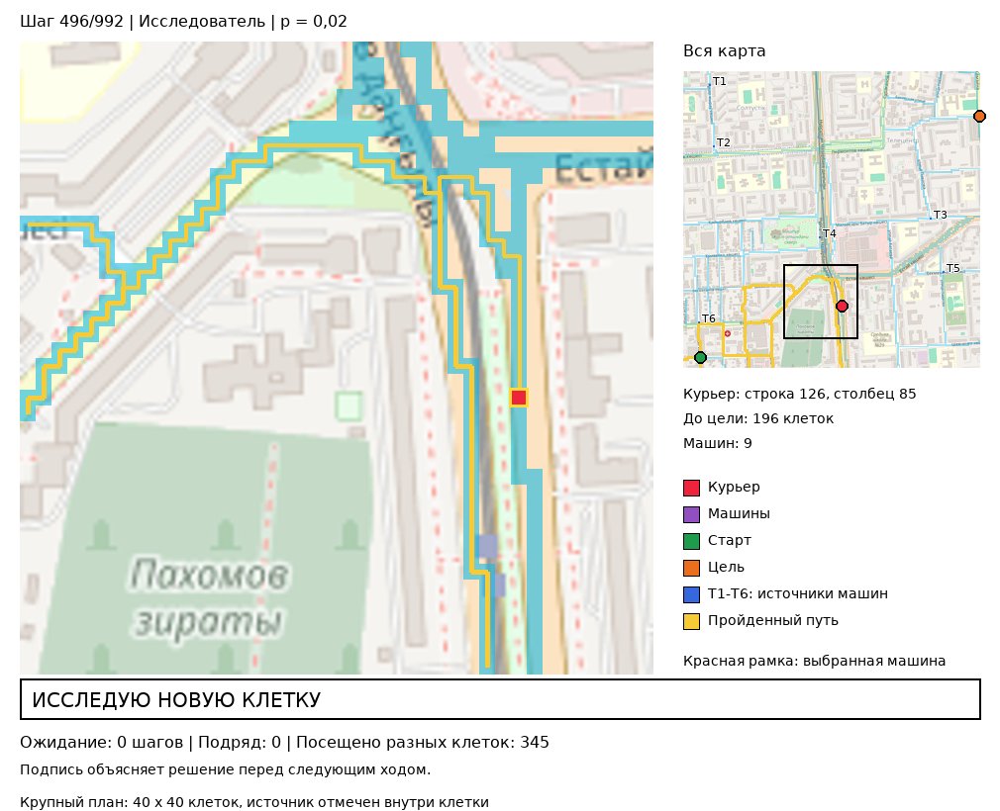

In [57]:
# Показываем кадр поездки и ссылку на полный GIF.
display(FileLink(animation_paths["explorer_start3_collision"].as_posix()))
display(Image(filename=str(RESULTS_DIR / "explorer_start3_collision_preview.png")))

### Осторожный объезд: путь вокруг источника Т3 со старта 2 (эпизод 97)

Без ожидания курьер проходит 228 шагов вместо кратчайших 170: путь заранее обходит источник машин Т3. Это та же поездка, что показана выше для двух других стратегий.

C:\UniProjects\rl-uni\results\cautious_start2_detour_success.gif

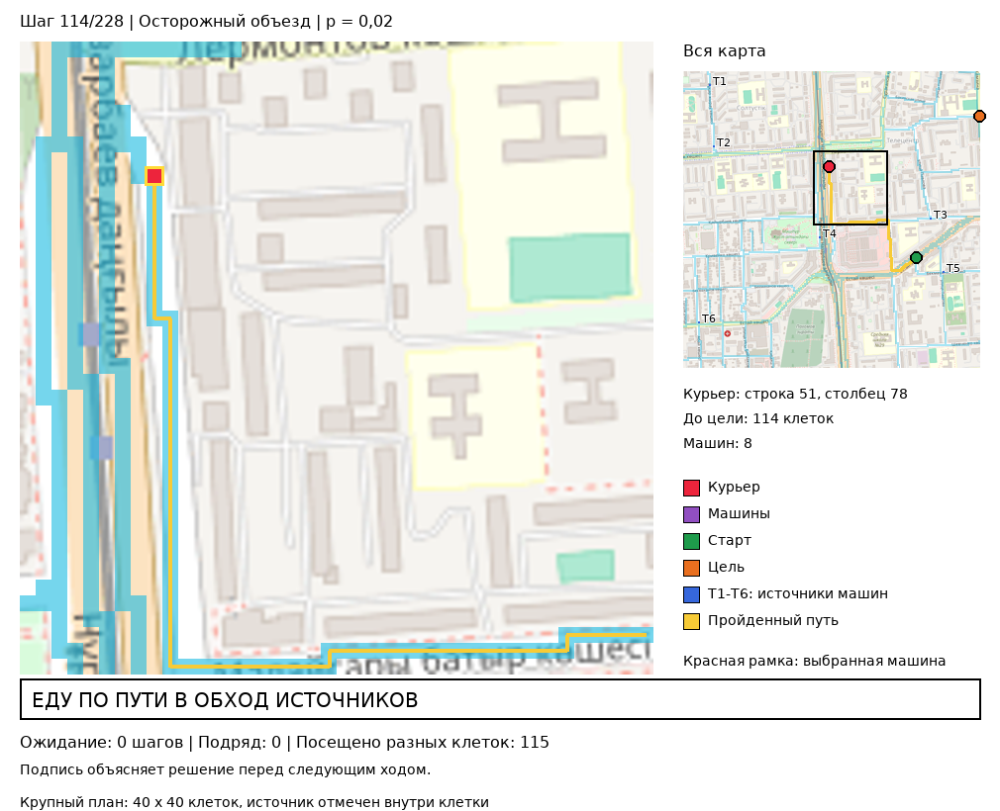

In [58]:
# Показываем кадр поездки и ссылку на полный GIF.
display(FileLink(animation_paths["cautious_start2_detour_success"].as_posix()))
display(Image(filename=str(RESULTS_DIR / "cautious_start2_detour_success_preview.png")))

## 9. Выводы

Ниже приведены подробные таблицы для всех значений p, рассчитанные из всех поездок.
Исследователь проверяет больше участков и тратит больше шагов. Нетерпеливый кратчайший движется к цели и отклоняется при опасности. Осторожный объезд выбирает путь с учётом источников и может ждать.

Долгое исследование увеличивает время контакта с трафиком; ожидание тоже не гарантирует безопасность. Для оценки нужны и доля доставок, и затраченное время. Отдельные GIF объясняют поведение, а выводы о надёжности опираются на 500 поездок на условие.
Модель приближает улицы клетками и не учитывает реальные правила движения.

In [59]:
# Показываем таблицу без служебного столбца номеров строк.
from IPython.display import HTML

# Собираем подробные результаты для всех вероятностей появления машин.
all_probabilities_table = condition_summary.reset_index()
all_probabilities_table["policy"] = all_probabilities_table["policy"].replace(STRATEGY_NAMES)
all_probabilities_table = all_probabilities_table.rename(columns={
    "start": "Старт", "policy": "Стратегия", "delivery_count": "Доставки",
    "episode_count": "Всего поездок", "success_percent": "Успех, %",
    "successful_steps": "Шаги при успехе"})
all_probabilities_table = all_probabilities_table[[
    "rate", "Старт", "Стратегия", "Доставки", "Всего поездок",
    "Успех, %", "Шаги при успехе"]]
all_probabilities_table.to_csv(RESULTS_DIR / "condition_summary.csv", index=False)

# Показываем девять сочетаний старта и стратегии при p = 0.
table_for_probability = all_probabilities_table[all_probabilities_table.rate == 0]
display(HTML(table_for_probability.drop(columns="rate").round(2).to_html(index=False)))

Старт,Стратегия,Доставки,Всего поездок,"Успех, %",Шаги при успехе
1,Исследователь,500,500,100.0,2267.37
1,Нетерпеливый кратчайший,500,500,100.0,201.00
1,Осторожный объезд,500,500,100.0,201.00
2,Исследователь,500,500,100.0,2615.54
2,Нетерпеливый кратчайший,500,500,100.0,170.00
2,Осторожный объезд,500,500,100.0,170.00
3,Исследователь,500,500,100.0,2551.75
3,Нетерпеливый кратчайший,500,500,100.0,286.00
3,Осторожный объезд,500,500,100.0,286.00


In [60]:
# Показываем девять сочетаний старта и стратегии при p = 0.005.
table_for_probability = all_probabilities_table[all_probabilities_table.rate == 0.005]
display(HTML(table_for_probability.drop(columns="rate").round(2).to_html(index=False)))

Старт,Стратегия,Доставки,Всего поездок,"Успех, %",Шаги при успехе
1,Исследователь,448,500,89.6,2245.97
1,Нетерпеливый кратчайший,495,500,99.0,210.50
1,Осторожный объезд,498,500,99.6,212.03
2,Исследователь,452,500,90.4,2462.59
2,Нетерпеливый кратчайший,495,500,99.0,179.25
2,Осторожный объезд,500,500,100.0,228.03
3,Исследователь,465,500,93.0,2469.97
3,Нетерпеливый кратчайший,497,500,99.4,289.67
3,Осторожный объезд,500,500,100.0,288.44


In [61]:
# Показываем девять сочетаний старта и стратегии при p = 0.02.
table_for_probability = all_probabilities_table[all_probabilities_table.rate == 0.02]
display(HTML(table_for_probability.drop(columns="rate").round(2).to_html(index=False)))

Старт,Стратегия,Доставки,Всего поездок,"Успех, %",Шаги при успехе
1,Исследователь,298,500,59.6,2143.99
1,Нетерпеливый кратчайший,467,500,93.4,227.37
1,Осторожный объезд,471,500,94.2,231.35
2,Исследователь,383,500,76.6,2223.45
2,Нетерпеливый кратчайший,470,500,94.0,201.56
2,Осторожный объезд,500,500,100.0,228.03
3,Исследователь,380,500,76.0,2378.03
3,Нетерпеливый кратчайший,490,500,98.0,298.66
3,Осторожный объезд,500,500,100.0,293.15


In [62]:
# Показываем девять сочетаний старта и стратегии при p = 0.05.
table_for_probability = all_probabilities_table[all_probabilities_table.rate == 0.05]
display(HTML(table_for_probability.drop(columns="rate").round(2).to_html(index=False)))

Старт,Стратегия,Доставки,Всего поездок,"Успех, %",Шаги при успехе
1,Исследователь,163,500,32.6,2077.95
1,Нетерпеливый кратчайший,392,500,78.4,247.57
1,Осторожный объезд,392,500,78.4,264.26
2,Исследователь,323,500,64.6,1986.80
2,Нетерпеливый кратчайший,421,500,84.2,227.31
2,Осторожный объезд,500,500,100.0,228.26
3,Исследователь,304,500,60.8,2303.88
3,Нетерпеливый кратчайший,442,500,88.4,311.13
3,Осторожный объезд,497,500,99.4,297.84
